version: 0.1.6

In [ ]:
from __future__ import print_function
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import yaml
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
from matplotlib.ticker import FuncFormatter
from PIL import Image, ImageDraw, ImageFont, ImageSequence
from pathlib import Path
import os
import re
import math

### Config

In [ ]:
config = {
    "version": "0.1.6",
    "hamiltonian": {
        "kind": "qwz",# "qwz", "qwz analytic", "mos2" or "haldane"
        "params": {
            "M": 1.1#, #QWZ 1.1 Haldane 0.1
            #"phi": 0.3 #Haldane
        }
        #MoS2
        #"terms": [""],  # e.g., [] | ["soc"] | ["zeeman"] | ["modified"] | ["soc","zeeman"]
        #"params": {
        #    "soc": {                 # present only if "soc" in terms
        #       "lambda": 0.073
        #   },
        #   "zeeman": {              # present only if "zeeman" in terms
        #       "B": [0.05, 0.05, 0.07],
         #   },
            #"modified": {            # present only if "modified" in terms
             #   "delta": 0.1
            #}
       # }
    },
    "NQ": 17,
    "Grid": "extend", #sew/extend handle grid logic
    "Range": "foreward", #foreward (0,2pi), center (-pi,pi)
    "v_band": 0,
    "c_band": 1,
    "epsilon": 1e-14,
    "U": 5,
    "eps1": 0,
    "eps2": 0,
    "n_Fs": 1, #number of quantized exciton bands, only good if you already know ahead of time how many you will have
    "interaction": {                 # replaces ("Constant", x, d) | ("Coulomb", None, None)
        "kind": "constant",          # "constant" | "coulomb" | "seperable"
        "params": {"vx": 1, "vd": 0}   # for "constant"; empty for "coulomb"
    },
    "RunType": "Local" #"Local" "Cluster"
}
#"Interaction":("Constant",1,1)
#"Interaction":("Coulomb",None,None)
#with open('configs/haldane.yml', 'w') as outfile:
#   yaml.dump(config, outfile, default_flow_style=False)
SaveConfig('configlocal.yml',config)

In [ ]:
def GetConfig(filename):
    with open(filename, 'r') as stream:
        try:
            cfg = yaml.load(stream, Loader=yaml.UnsafeLoader)
        except TypeError:
            cfg = yaml.load(stream)
    hc = cfg["hamiltonian"]
    hkind = hc["kind"]
    if hkind in{"haldane","mos2"}:
        ltype =  "hexagonal"
    elif hkind in {"qwz", "qwz analytic"}:
        ltype = "square"
    else:
        raise ValueError(f"Lattice type not configured: \"{hkind}\"")
    hc["lattice"] = ltype
    terms: List[str] = [t for t in hc.get("terms", [])]
    if hkind in {'qwz', "haldane", "qwz analytic"}:
        cfg["Bands"] = 2
    elif hkind == 'mos2':
        cfg["Bands"] = 6 if any(t in {"zeeman", "soc"} for t in terms) else 3
    HandleGridConfig(cfg)
    return cfg

def HandleGridConfig(cfg):
    NQ = cfg["NQ"]
    grid_handle = cfg.get("Grid","extend")
    range_handle = cfg.get("Range","center")
    ltype = cfg["hamiltonian"]["lattice"]
    if grid_handle == "extend":
        Nk = NQ
    elif grid_handle == "sew":
        Nk = 2*NQ
    if range_handle == "foreward":
        k_frac = np.linspace(0,1,Nk,endpoint=False)
        Q_frac = np.linspace(0,1,NQ,endpoint=False)
    elif range_handle == "center":
        k_frac = np.linspace(-0.5,0.5,Nk,endpoint=False)
        Q_frac = np.linspace(-0.5,0.5,NQ,endpoint=False)
    else:
        raise Exception("wrong range handle")
    if ltype == "square":
        b1 = (2*np.pi,0)
        b2 = (0,2*np.pi)
    elif ltype == "hexagonal":        
        b1 = (2*np.pi/3,2*np.pi/np.sqrt(3))
        b2 = (-2*np.pi/3,2*np.pi/np.sqrt(3))
    b = [np.array(b1), np.array(b2)]
    cfg["Nk"] = Nk
    cfg["rec_vec"] = b
    cfg["k_frac"] = k_frac
    cfg["Q_frac"] = Q_frac
    return

#for the py file
def SaveConfig(config_file,cfg):
    keys_to_save = ["version", "hamiltonian", "NQ", "Grid", "U", "epsilon","interaction","c_band","v_band","eps1","eps2","n_Fs","RunType","Range"]
    config = {key: cfg.get(key) for key in keys_to_save if key in cfg}
    with open(config_file, 'w') as outfile:
        yaml.dump(config, outfile, default_flow_style=False)

note the convention for the vectors above, NN distance = 1, matters for hexagonal reciprocal vector length

In [ ]:
def FracString(num,denom):
    return rf"\frac{{{num}}}{{{denom}}}"
def MomentumString(ind,nk,k_max_num,k_max_denom):
    return rf"{FracString(ind,nk)}\,{FracString(k_max_num,k_max_denom)}"
def PiFormatter(value, tick_number):#legacy
    return f"{np.round(value/np.pi,3)}π"
def sanitize_filename(s: str) -> str:
    # Replace invalid characters with underscore
    return re.sub(r'[<>:"/\\|?*]', '_', s)

In [ ]:
%matplotlib widget

### PBC
PBC for a Hexagonal BZ Parametrized to a rectangle, see geometry in notebook.
adds indices with PBC considering rectangular parametrization, k1 and k2 are the indices of the two vectors in klist (or Qlist if it is only Q1+Q2) otherwise (k+Q) convert to k indices in accordance with $m=\frac{\Delta k}{\Delta Q}$ $k_{ind} = m\cdot Q_{ind}$ before calling the function

I will use a cylindrical gauge (parralel transport on kx) so tha phase seam is at the edge, this way the phase jump for momentum addition is calculable according to https://www.overleaf.com/read/nnygbhsqhrmz#d4fd04

In [ ]:
def PBCAddInd(k_wrap,delta,N):
    """
    k_wrap: (i,j,nx,ny) representing the coord in the first BZ and how many wraps on each
    delta: just id,jd
    works in all lattice types since using the parallelogram BZ (acts like square when using i*b1+j*b2)
    """
    i,j,nx,ny = k_wrap
    di, dj = delta
    sx = i + di
    sy = j + dj
    dnx = sx // N
    dny = sy // N
    ix = sx % N
    jy = sy % N
    return ix, jy, nx+dnx, ny+dny

In [ ]:
def UnitPhase(z, eps=1e-14):
    a = np.abs(z)
    return z / (a + eps)

def ParallelTransportCylindrical(u, enforce_ky_periodic=True):
    """
    u: shape (Nx, Ny, Norb, Nband), normalized.
    Returns u_g in cylindrical gauge:
      1) ky-parallel transport on i=0 column
      2) optional ky-periodic sewing on i=0 column
      3) x-parallel transport on each ky row
    note: for hexagonal the coordinates of u are u[b1,b2,orb,band]
    """
    u_g = np.zeros_like(u, dtype=np.complex128)
    Nx, Ny, Norb, Nband = u.shape

    for band in range(Nband):
        # ------------------------------------------------------------
        # 1) Seed at (0,0)
        # ------------------------------------------------------------
        u_g[0, 0, :, band] = u[0, 0, :, band]

        # ------------------------------------------------------------
        # 2) Parallel transport along ky on the i=0 column
        # ------------------------------------------------------------
        for j in range(Ny - 1):
            z = np.vdot(u_g[0, j, :, band], u[0, j + 1, :, band])   # <j|j+1>
            u_g[0, j + 1, :, band] = np.conj(UnitPhase(z)) * u[0, j + 1, :, band]

        # ------------------------------------------------------------
        # 3) Enforce trivial ky sewing on the i=0 column (optional)
        #    Spread the end-point mismatch uniformly over ky
        # ------------------------------------------------------------
        if enforce_ky_periodic:
            z_end = np.vdot(u_g[0, Ny - 1, :, band], u_g[0, 0, :, band])
            theta = np.angle(z_end)

            for j in range(Ny):
                u_g[0, j, :, band] *= np.exp(-1j * j * theta / Ny)

        # ------------------------------------------------------------
        # 4) Parallel transport along x on each ky row,
        #    seeded by the ky-fixed first column
        # ------------------------------------------------------------
        for j in range(Ny):
            for i in range(Nx - 1):
                z = np.vdot(u_g[i, j, :, band], u[i + 1, j, :, band])   # <i|i+1>
                u_g[i + 1, j, :, band] = np.conj(UnitPhase(z)) * u[i + 1, j, :, band]

    return u_g

In [ ]:
def SeamPhaseGx(u_g):
    #convention, use gx[j,n] for the target ky of ind j
    """
    u_g: (Nx,Ny,Norb,Nband) after parallel gauge in x (or axis 11 for non square)
    returns gx: (Ny,Nband) complex unimodular
    """
    Nx, Ny, _ , Nband= u_g.shape
    gx = np.empty((Ny,Nband), dtype=complex)
    for band in range(Nband):
        for j in range(Ny):
            z = np.vdot(u_g[Nx-1, j,:,band], u_g[0, j,:,band])
            gx[j,band] = z / (np.abs(z) + 1e-14)
    return gx

def u_ext(u, gx, K, band):
    i, j, nx, ny = K
    # cylindrical gauge: seam only in x (1 for non square)
    phase = gx[j, band]**nx
    return phase * u[i, j, :, band]

# Non interacting picture

## Solve non-interacting BZ

### Hamiltonians

In [ ]:
def QWZHamiltonian(kx,ky,M):
    pauli_mat =[np.array([[0,1],[1,0]]), np.array([[0,-1j],[1j,0]]), np.array([[1,0],[0,-1]])]
    return np.sin(kx)*pauli_mat[0] + np.sin(ky)*pauli_mat[1] + (M+np.cos(kx)+np.cos(ky))*pauli_mat[2]
def HaldaneH(kx, ky, t1=1.0, t2=0.1, phi=0, M=0, a=1.0):
    d = np.array([
        [-a, 0.0],
        [ a/2.0, -np.sqrt(3)*a/2.0],
        [ a/2.0,  np.sqrt(3)*a/2.0],
    ])
    b = np.vstack([d[1] - d[2] , d[2] - d[0],d[0] - d[1]])
    k = np.array([kx, ky])
    f = np.exp(1j * (k @ d.T)).sum()
    cb = np.cos(k @ b.T).sum()
    sb = np.sin(k @ b.T).sum()
    d0 = 2.0 * t2 * np.cos(phi) * cb
    dz = M - 2.0 * t2 * np.sin(phi) * sb
    H = np.array([[d0 + dz, -t1 * f],
                  [-t1 * np.conj(f), d0 - dz]], dtype=complex)
    return H
# 10.1103/PhysRevB.88.085433
def TNNMoS_2Hamiltonian(kx,ky,terms,params):
    params = hcfg.get("params", {})
    has_soc    = "soc" in terms
    has_zeeman = "zeeman" in terms
    alpha =0.5*kx
    beta = (np.sqrt(3)/2)*ky
    epsilon1 =0.683
    epsilon2 =1.707
    t0 = -0.146
    t1 = -0.114
    t2 = 0.506
    t11 = 0.085
    t12 = 0.162
    t22 = 0.073
    r0 = 0.060
    r1 = -0.236
    r2 = 0.067
    r11 = 0.016
    r12 = 0.087
    u0 = -0.038
    u1 = 0.046
    u2 = 0.001
    u11 = 0.266
    u12 = -0.176
    u22 = -0.150
    if "modified" in terms:
        delta = params.get("modified").get("delta",0.0)
    else:
        delta = 0.0
    h0 = (epsilon1 +
          2 * t0 * (2 * np.cos(alpha) * np.cos(beta) + np.cos(2 * alpha)) +
          2 * r0 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
          2 * u0 * (2 * np.cos(2 * alpha) * np.cos(2 * beta) + np.cos(4 * alpha)))

    h1_real = (-2 * np.sqrt(3) * t2 * np.sin(alpha) * np.sin(beta) +
               2 * (r1 + r2) * np.sin(3 * alpha) * np.sin(beta) -
               2 * np.sqrt(3) * u2 * np.sin(2 * alpha) * np.sin(2 * beta))

    h1_imag = (2 * t1 * np.sin(alpha) * (2 * np.cos(alpha) + np.cos(beta)) +
               2 * (r1 - r2) * np.sin(3 * alpha) * np.cos(beta) +
               2 * u1 * np.sin(2 * alpha) * (2 * np.cos(2 * alpha) + np.cos(2 * beta)))

    h1 = h1_real + 1j * h1_imag

    h2_real = (2 * t2 * (np.cos(2 * alpha) - np.cos(alpha) * np.cos(beta)) -
               (2 / np.sqrt(3)) * (r1 + r2) * (np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
               2 * u2 * (np.cos(4 * alpha) - np.cos(2 * alpha) * np.cos(2 * beta)))

    h2_imag = (2 * np.sqrt(3) * t1 * np.cos(alpha) * np.sin(beta) +
               (2 / np.sqrt(3)) * np.sin(beta) * (r1 - r2) * (np.cos(3 * alpha) + 2 * np.cos(beta)) +
               2 * np.sqrt(3) * u1 * np.cos(2 * alpha) * np.sin(2 * beta))

    h2 = h2_real + 1j * h2_imag

    h11 = (epsilon2 +
           (t11 + 3 * t22) * np.cos(alpha) * np.cos(beta) +
           2 * t11 * np.cos(2 * alpha) +
           4 * r11 * np.cos(3 * alpha) * np.cos(beta) +
           2 * (r11 + np.sqrt(3) * r12) * np.cos(2 * beta) +
           (u11 + 3 * u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u11 * np.cos(4 * alpha)+delta)

    h12_real = (np.sqrt(3) * (t22 - t11) * np.sin(alpha) * np.sin(beta) +
                4 * r12 * np.sin(3 * alpha) * np.sin(beta) +
                np.sqrt(3) * (u22 - u11) * np.sin(2 * alpha) * np.sin(2 * beta))

    h12_imag = (4 * t12 * np.sin(alpha) * (np.cos(alpha) - np.cos(beta)) +
                4 * u12 * np.sin(2 * alpha) * (np.cos(2 * alpha) - np.cos(2 * beta)))

    h12 = h12_real + 1j * h12_imag

    h22 = (epsilon2 + 
           (3 * t11 + t22) * np.cos(alpha) * np.cos(beta) +
           2 * t22 * np.cos(2 * alpha) +
           2 * r11 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
           (2 / np.sqrt(3)) * r12 * (4 * np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
           (3 * u11 + u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u22 * np.cos(4 * alpha)-delta)

    # Construct the Hamiltonian matrix
    H_0 = np.array([
        [h0, h1, h2],
        [np.conj(h1), h11, h12],
        [np.conj(h2), np.conj(h12), h22]
    ])
    if not has_soc and not has_zeeman:
        return H_0
    sx = np.array([[0., 1.],
                   [1., 0. ]], dtype=complex)
    sy = np.array([[0., -1j],
                   [1j,  0. ]], dtype=complex)
    sz = np.array([[1., 0. ],
                   [0., -1.]], dtype=complex)

    # Base in spinful space: diag(H0, H0)  (6x6)
    H_spinful = np.block([
        [H_0,               np.zeros_like(H_0)],
        [np.zeros_like(H_0), H_0             ]
    ])
    if has_zeeman:
        B = np.array(params.get("zeeman", {}).get("B", [0.0, 0.0, 0.0]), dtype=float)
        if B.shape != (3,):
            raise ValueError("Zeeman.B must be a length-3 array/list [Bx, By, Bz].")
        H_spin = B[0]*sx + B[1]*sy + B[2]*sz           # 2x2
        H_zeeman = np.kron(np.eye(3, dtype=complex), H_spin)  # 6x6
        H_spinful = H_spinful + H_zeeman
    if has_soc:
        # lambda_soc from config if present; fallback to 0.073
        lambda_soc = params.get("soc", {}).get("strength", 0.073)
        Lz = np.array([[0,  0,   0 ],
                       [0,  0,  2j ],
                       [0, -2j,  0 ]], dtype=complex)

        SOC_block = (lambda_soc / 2.0) * Lz  # 3x3
        # Expand to spin basis: +SOC on ↑, -SOC on ↓
        SOC_full = np.block([
            [ SOC_block,               np.zeros_like(SOC_block)],
            [ np.zeros_like(SOC_block), -SOC_block            ]
        ])
        H_spinful = H_spinful + SOC_full
    return H_spinful

### Analytic Solutions
we can also use the analytic solutions for the non interacting picture in our toy models

In [ ]:
def GetAnalyticQWZ(kx,ky,M):
    dx = np.sin(kx)
    dy = np.sin(ky)
    dz = M + np.cos(kx) + np.cos(ky)
    d  = np.sqrt(dx*dx + dy*dy + dz*dz)

    uvA = np.array([dz - d, dx + 1j*dy], dtype=complex)        # bad near d≈dz (north pole)
    uvB = np.array([dx - 1j*dy, -(dz + d)], dtype=complex)     # bad near d≈-dz (south pole)
    
    if abs(d + dz) > abs(dx - 1j*dy):
        uc = np.array([d + dz, dx + 1j*dy], dtype=complex)
    else:
        uc = np.array([dx - 1j*dy, d - dz], dtype=complex)

    # --- Valence band (E = -d) ---
    if abs(d - dz) > abs(dx - 1j*dy):
        uv = np.array([dz - d, dx + 1j*dy], dtype=complex)
    else:
        uv = np.array([dx - 1j*dy, -(d + dz)], dtype=complex)

    # Normalize
    uc /= np.linalg.norm(uc)
    uv /= np.linalg.norm(uv)

    evals = np.array([-d, d])
    evecs = np.column_stack((uv, uc))
    
    return evals, evecs

### Solve Hamiltonians

In [ ]:
def SolveH(kx,ky,hcfg):
    kind = hcfg.get("kind",None)
    if kind == "mos2":
        params = hcfg["params"]
        terms = set(map(str.lower, hcfg.get("terms", [])))
        H = TNNMoS_2Hamiltonian(kx,ky,terms,params)
    elif kind == "qwz":
        M = hcfg.get("params").get("M")
        H = QWZHamiltonian(kx,ky,M)
    elif kind =="haldane":
        params= hcfg.get("params")
        M_=params.get("M")
        phi_ = params.get("phi")
        H = HaldaneH(kx,ky,phi=phi_,M=M_)
    elif kind =="qwz analytic":
        M = hcfg.get("params").get("M")
        return GetAnalyticQWZ(kx,ky,M)
    else:
        raise ValueError("Could not parse acceptable Hamiltonian")
    #if we are here we are solving numerically
    val,evec = np.linalg.eigh(H)
    sorted_indices = np.argsort(val)
    sorted_val = val[sorted_indices]
    sorted_evec = evec[:, sorted_indices]
    return sorted_val,sorted_evec

def SolveBzNoninteracting(cfg):
    hcfg = cfg.get("hamiltonian")
    ltype = hcfg["lattice"]
    b = cfg["rec_vec"]
    k_frac = cfg["k_frac"]
    n_points = cfg["Nk"]
    n_bands = cfg["Bands"]
    dk_frac = 1/n_points
    eps1_factor = dk_frac*cfg.get("eps1",0)
    eps2_factor = dk_frac*cfg.get("eps2",0)
    (epsx,epsy) = b[0]*eps1_factor+b[1]*eps2_factor
    wf_BZ = np.zeros((n_points,n_points,n_bands,n_bands), dtype=complex) #k1,k2,orbital weight, band
    eval_BZ = np.zeros((n_points,n_points,n_bands))
    for i in range(n_points):
        for j in range(n_points):
            (kx,ky) = k_frac[i]*b[0] + k_frac[j]*b[1]
            (val,vec)=SolveH(kx+epsx,ky+epsy,hcfg)
            eval_BZ[i,j] = val
            wf_BZ[i,j] = vec
    wf_BZ[:,:,:,:] = ParallelTransportCylindrical(wf_BZ[:,:,:,:])
    return eval_BZ, wf_BZ

## Berry Curvature

In [ ]:
#recieves ni_wf[:,:,:,n] where n is the desired band
def GetBerryCurvature1band(u):
    N = u.shape[0] #assumes u.shape[N,N,:]
    link_x=np.zeros([N,N], dtype="complex")
    link_y=np.zeros([N,N], dtype="complex")
    BC=np.zeros([N,N], dtype="float")
    for i in range(N):
        for j in range(N):
            iL,jL,nxL,nyL = PBCAddInd((i,j,0,0),(-1,0),N) #all the n's are unused because everything here is in the first BZ
            iD,jD,nxD,nyD = PBCAddInd((i,j,0,0),(0,-1),N)
            num = np.vdot(u[iL, jL], u[i, j])
            link_x[i, j] = num / np.abs(num)
            num = np.vdot(u[iD, jD], u[i, j])
            link_y[i, j] = num / np.abs(num)
    for i in range(N):
        for j in range(N):
            iL,jL,nxL,nyL = PBCAddInd((i,j,0,0),(-1,0),N)
            iD,jD,nxD,nyD = PBCAddInd((i,j,0,0),(0,-1),N)
            val = np.imag(np.log(link_x[i,j]*link_y[iL,jL]/(link_x[iD,jD]*link_y[i,j])))
            BC[i,j] = val
    C=np.sum(BC)/(2*np.pi)
    return BC,C

## Check Band Structure

In [ ]:
def InterpEquidistant(points , n):
    x = points[:, 0]
    y = points[:, 1]
    
    # Linear length on the line
    distance = np.cumsum(np.sqrt( np.ediff1d(x, to_begin=0)**2 + np.ediff1d(y, to_begin=0)**2 ))
    distance = distance/distance[-1]
    
    fx, fy = interp1d( distance, x ), interp1d( distance, y )
    
    alpha = np.linspace(0, 1, n)
    x_regular, y_regular = fx(alpha), fy(alpha)
    path = np.column_stack((x_regular, y_regular))
    return path

In [ ]:
def GraphBands(output_folder,hcfg,title=None,filename=None):
    ltype = hcfg["lattice"]
    #define high symmetry points
    if ltype =="hexagonal":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([2*np.pi/3, 2*np.pi/(3*np.sqrt(3))])  # K point
        M = np.array([2*np.pi/3, 0])  # M point
    elif ltype == "square":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([np.pi, 0.0])  # K point
        M = np.array([np.pi, np.pi])  # M point
    else:
        raise ValueError("Could not parse acceptable Lattice type")
    points = np.array([Gamma, K, M, Gamma])
    k_path = InterpEquidistant(points, 300)
    evals = []
    for k in k_path:
        val,vec = SolveH(k[0],k[1],hcfg)
        evals.append(val)
    # Convert evals to NumPy array for easy plotting
    evals = np.array(evals)  # Shape: (300, num_bands)
    
    # Compute cumulative distances along k-path
    distances = [0.0]  # First point is at distance 0
    for i in range(1, len(k_path)):
        dist = np.linalg.norm(k_path[i] - k_path[i - 1])  # Euclidean distance
        distances.append(distances[-1] + dist)
    
    distances = np.array(distances)  # Convert to NumPy array
    
    # Find tick positions for Γ, K, and M in the distance array
    tick_positions = [0]  # Start with first point (Gamma)
    tick_labels = ["Γ"]  # Gamma point label
    
    cumulative_length = 0
    for i in range(len(points) - 1):
        segment_length = np.linalg.norm(points[i+1] - points[i])
        cumulative_length += segment_length
        tick_positions.append(cumulative_length)
    
    tick_labels.extend(["K", "M", "Γ"])  # Labels for symmetry points
    
    fig, ax = plt.subplots(figsize=(6, 5))

    # Loop over all bands
    for band in range(evals.shape[1]):
        ax.plot(distances, evals[:, band], color="black")

    # Add vertical lines at symmetry points
    for pos in tick_positions:
        ax.axvline(x=pos, color="gray", linestyle="--", linewidth=0.5)

    # Set x-axis ticks and labels
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)

    # Labels and title
    ax.set_xlabel("Wavevector k")
    ax.set_ylabel("Energy (eV)")  # Adjust units if needed
    ax.set_title(f"{title}")

    # Save and show
    output_path = os.path.join(
    output_folder,
    sanitize_filename(f"{filename}.png"))  
    fig.savefig(output_path)

# Interacting picture

## The Plan
following 10.1103/PhysRevB.91.075310
1) Solve the Hamiltonian for the entire $(k_x,k_y)$ grid in the non interacting picture (above)
2) Function create the Hamiltonian with interaction (direct and exchange terms) using the non interacting eigenvectors eq (6)

$D_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{k}-\vec{k'}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k'}+\vec{Q}}\right)_{cc'}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k}}\right)_{v'v}$

$X_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{Q}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k}}\right)_{cv}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k'}+\vec{Q}}\right)_{v'c'}$

Use the non interacting eigenvalues as well as D and X in the following equation (5)

$
\begin{equation}
\langle v, c, \vec{k}, \vec{Q} | H | v', c', \vec{k'}, \vec{Q'} \rangle = \delta_{vv'} \delta_{cc'} \delta_{kk'} \left( \epsilon_{(\vec{k} + \vec{Q}) c} - \epsilon_{\vec{k} v}\right) - (D - X)^{c c'}_{v v'} (\vec{k}, \vec{k'}, \vec{Q}) 
\end{equation}
$

3) loop over every Q leading to eigenvalues $\epsilon_Q$ and eigenvectors $F(Q,P)$
4) graph e_q and integrated F

### Step 1 Solve tight binding
use the previous functions to get 2D eigenfunc matrix of the entire BZ, run non pythTB block for entire BZ.<br>
eigenvalues [k_x][k_y][n]. conduction: n = 0, valance: n = 1.<br>
eigenvectors [kx][ky][j][n] x: j=0, y: j=1

In [ ]:
cfg = GetConfig("configlocal.yml")
hcfg = cfg["hamiltonian"]; 
GraphBands("Images/Tests",hcfg,f"Band Structure {hcfg['kind']}",f"band_structure_{hcfg['kind']}")

In [ ]:
cfg = GetConfig("configqwz.yml")
ni_eval, ni_wf = SolveBzNoninteracting(cfg)
#ref = np.array([1, 0], dtype=complex)
#phase = np.angle(np.einsum('xyi,i->xy', ni_wf[:, :, :, 0], np.conj(ref)))
GraphFromConfig(ni_eval[:,:,1],cfg,GraphProtocol.NiE2D,"Images/Tests",0)
n_bands = cfg.get("Bands")
for n in range(n_bands):
    BC, C = GetBerryCurvature1band(ni_wf[:,:,:,n])
    GraphFromConfig(BC,cfg,GraphProtocol.NiBC,"Images/Tests",n,C=C)
    print(f"band {n} C={C}")

### Step 2 build Bethe-Salpeter kernal
$
\begin{equation}
\langle v, c, \vec{k}, \vec{Q} | H | v', c', \vec{k'}, \vec{Q'} \rangle = \delta_{vv'} \delta_{cc'} \delta_{kk'} \left( \epsilon_{(\vec{k} + \vec{Q}) c} - \epsilon_{\vec{k} v}\right) - (D - X)^{c c'}_{v v'} (\vec{k}, \vec{k'}, \vec{Q}) 
\end{equation}
$

$D_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{k}-\vec{k'}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k'}+\vec{Q}}\right)_{cc'}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k}}\right)_{v'v}$

$X_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{Q}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k}}\right)_{cv}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k'}+\vec{Q}}\right)_{v'c'}$

$
\begin{equation}
k_v = p-Q/2
\end{equation}
$

$
\begin{equation}
k_c = p+Q/2
\end{equation}
$

Define func get_H(Q,wf_array) which returns the 6D H tensor for each Q depending on the wavefunctions of the non interacting problem. The indices of the tensor are kx,ky,d,kx',ky',d' where d are the original orbital basis.
notes: currently assumes a 2 band system, therfore no consideration for difference between different bands c=c' v=v'.

#### GetH2Band
in 2band $H_{cc'}^{vv'} == H_c^v$ currently calculates for v=v'=0 c=c'=1
in multiple bands we define ahead of time which bands are valence and which ar conduction and loop over those bands.
4 dimensions c,c',v,v': say vband =[0,1] cband=[2,3] are the indices of the valance and conduction bands then we have two options for each v,v' (either 0 or 1 each) and two options for c,c' (either 2,3 each). This means its H[(kx,ky),(kx_tag,ky_tag),c,c',v,v'], after that we need to squish this H to H_squish1[(kx,ky),(kx_tag,ky_tag),cc',vv'] -> H_squish2[[(kx,ky),(kx_tag,ky_tag),cc'vv']-> H_squish3[(kx,ky)(kx_tag,ky_tag),cc'vv']-> squish4 [(kx,ky)(kx',ky')cc'vv']-> squish5 [(kx,ky)kx'ky'cc'vv'] (where squish 5 is just like the first squish from 4d to 2d. basically we go from 8D to 2D in a manner that is bijective.

#### didnt read all that 
anyways the band is just another index, literally the same way it is in the code with eig_vec[kx,ky,n]

In [ ]:
def GetH2Band(Q1,Q2,ni_wf,ni_evals,cfg,g1): #g1 is gx I couldnt decide on a convention that was logical for me
    U = cfg["U"]
    epsilon = cfg["epsilon"]
    [b1,b2] = cfg["rec_vec"]
    k_frac = cfg["k_frac"]
    Nk = cfg["Nk"]
    range_handle = cfg["Range"]
    interaction = cfg["interaction"]
    params = interaction["params"]
    c_band = cfg["c_band"]
    v_band = cfg["v_band"]
    #weight for integral from Jacobian and dk1 dk2
    Jacobian = np.abs(b1[0]*b2[1] - b1[1]*b2[0])
    wk = Jacobian/pow(Nk,2)
    if range_handle == "foreward":
        q1i = Q1
        q2i = Q2
    elif range_handle == "center":
        NQ = cfg["NQ"]
        q1i = Q1 - NQ//2
        q2i = Q2 - NQ//2        
    H = np.zeros((Nk,Nk,Nk,Nk), dtype = complex) #p1,p2,p1',p2'
    for p1 in range(Nk):
        for p2 in range(Nk):
            Kp = (p1,p2,0,0)
            Kv = PBCAddInd(Kp,(-q1i,-q2i),Nk)
            Kc = PBCAddInd(Kp,(q1i,q2i),Nk)
            for p1p in range(Nk):
                for p2p in range(Nk):
                    Kpp = (p1p,p2p,0,0)
                    Kvp = PBCAddInd(Kpp,(-q1i,-q2i),Nk)
                    Kcp = PBCAddInd(Kpp,(q1i,q2i),Nk)
                    if p1==p1p and p2==p2p:
                        e = ni_evals[Kc[0]][Kc[1]][c_band]- ni_evals[Kv[0]][Kv[1]][v_band]
                    else:
                        e = 0
                    if interaction.get("kind") == "coulomb":
                        Q_frac = cfg["Q_frac"]
                        V_d_weight = params.get('vd',1)
                        V_x_weight = params.get('vx',1)
                        k_vec = np.array(k_frac[Kv[0]]*b1 + k_frac[Kv[1]]*b2)
                        k_vecp = np.array(k_frac[Kvp[0]]*b1 + k_frac[Kvp[1]]*b2)
                        deltak_vec = k_vec-k_vecp
                        deltak_norm  = np.linalg.norm(deltak_vec)
                        V_d = V_d_weight/(deltak_norm+epsilon)
                        if p1==p1p and p2==p2p:
                            V_d = 0
                        Q_vec = np.array(Q_frac[Q1]*b1 + Q_frac[Q2]*b2)
                        Q_norm  = np.linalg.norm(Q_vec)
                        V_x = V_x_weight/(Q_norm+epsilon)
                    elif interaction.get("kind") == "constant":
                        V_d = params.get('vd')
                        V_x = params.get('vx')
                    elif interaction.get("kind") == "seperable":
                        V = params.get('vx')
                        #<u_c(p+Q/2)|u_c(p-Q/2)><u_v(p'-Q/2)|u_v(p'+Q/2)>
                        # <u_c(Kc)|u_c(Kv)><u_v(Kv)|u_v(Kc)>
                        uc_c = u_ext(ni_wf,g1,Kc,c_band)
                        uc_v = u_ext(ni_wf,g1,Kv,c_band)
                        uv_vp = u_ext(ni_wf,g1,Kvp,v_band)
                        uv_cp = u_ext(ni_wf,g1,Kcp,v_band)
                        I = U*V*np.vdot(uc_c,uc_v)*np.vdot(uv_vp,uv_cp)
                        H[px,py,pxp,pyp] = e - wk*I
                        continue
                    else:
                        raise ValueError("Could not parse acceptable interaction kind")
                    uc = u_ext(ni_wf,g1,Kc,c_band)
                    uv = u_ext(ni_wf,g1,Kv,v_band)
                    ucp = u_ext(ni_wf,g1,Kcp,c_band)
                    uvp = u_ext(ni_wf,g1,Kvp,v_band)
                    D = U*V_d*np.vdot(uc, ucp) * np.vdot(uvp, uv)
                    X = U*V_x*np.vdot(uc, uv) * np.vdot(uvp, ucp)
                    H[px,py,pxp,pyp] = e - wk*(D-X)
    return H

### Step 3 Solve interaction
Loop over every Q in the 2BZ using a 2x difference between k's (so if k is 20x20 Q is 40x40). Flatten H to a 2D matrix. Solve the eigensystem of the 2D matrix, save the eigenvalues of Q.

In [ ]:
def SolveInteracting(ni_evals,ni_wf,cfg,gx):
    Nk = cfg["Nk"]
    NQ = cfg["NQ"]
    eQ_matrix = np.zeros((NQ,NQ,Nk*Nk))
    f_matrix = np.zeros((NQ, NQ, Nk, Nk, Nk*Nk), dtype=np.complex128)
    for i in range(NQ):#Qx
        for j in range(NQ):#Qy
            H_Q = GetH2Band(i,j,ni_wf,ni_evals,cfg,gx)
            s = H_Q.shape
            H_Q2D = H_Q.reshape(s[0]*s[1], s[2]*s[3]) #p_ij,p'_ij
            e_Q, f_Q = np.linalg.eigh(H_Q2D)
            sorted_indices = np.argsort(e_Q)
            sorted_e_Q = e_Q[sorted_indices]
            sorted_f_Q = f_Q[:, sorted_indices]
            sorted_f_Q_pxpy = sorted_f_Q.reshape(Nk, Nk, Nk*Nk)
            sorted_e_Q = np.real(sorted_e_Q)
            eQ_matrix[i,j]= sorted_e_Q
            f_matrix[i,j] = sorted_f_Q_pxpy
    return(eQ_matrix,f_matrix)

#### Parallel code
save ni_wf and ni_evals to disc, then send workers for each Q.

In [ ]:
from concurrent.futures import ProcessPoolExecutor, as_completed
import multiprocessing
def _SavePerQ(path, i, j, e_all, f_keep, meta=None):
    """Save per-Q results atomically."""
    path = Path(path)
    tmp = path / f"Q_{i:03d}_{j:03d}.tmp.npz"
    out = path / f"Q_{i:03d}_{j:03d}.npz"

    np.savez_compressed(tmp, e_all=e_all, f_keep=f_keep, meta=meta or {})
    os.replace(tmp, out)
    return out

def SolveOneQTask(Qx, Qy, cfg, ni_wf_path, ni_evals_path, gx_path, outdir):    
    """
    Worker function executed in each process.
    Qx, Qy, cfg_path, ni_wf_path, ni_evals_path, gx_path, outdir
    """
    n_Fs = cfg["n_Fs"]
    # Large arrays: mmap_mode="r" avoids copying; workers open read-only
    ni_wf = np.load(ni_wf_path, mmap_mode="r")
    ni_evals = np.load(ni_evals_path, mmap_mode="r")
    gx = np.load(gx_path, mmap_mode="r")

    # The function GetH2Band must accept these mmap arrays
    try:
        H_Q = GetH2Band(Qx, Qy, ni_wf, ni_evals, cfg, gx)
    except Exception as e:
        # propagate error in a readable way for the driver
        raise RuntimeError(f"GetH2Band failed for Q=({Qx},{Qy}): {e}")

    s = H_Q.shape
    Nk = cfg["Nk"]
    Nk2 = s[0] * s[1]  # should equal Nk*Nk
    H_Q2D = H_Q.reshape(Nk2, Nk2)

    # dense diagonalization; can be swapped later for eigsh/LinearOperator
    e_Q, f_Q = scipy.linalg.eigh(H_Q2D)
    sorted_indices = np.argsort(e_Q)
    sorted_e_Q = np.real(e_Q[sorted_indices])

    # Keep only n_Fs eigenvectors if requested
    if n_Fs is None or n_Fs <= 0:
        n_keep = Nk2
    else:
        n_keep = min(n_Fs, Nk2)

    sorted_f_Q = f_Q[:, sorted_indices[:n_keep]]   # shape (Nk2, n_keep)
    # reshape to (Nk, Nk, Nk2) if you want original px/py layout
    # But for compact storage we store flattened vectors: (Nk2, n_keep)
    f_keep = sorted_f_Q  # (Nk2, n_keep)

    # Meta
    meta = {
        "Qx": int(Qx), "Qy": int(Qy),
        "Nk": int(Nk),
        "Nk2": int(Nk2),
        "NQ": int(cfg["NQ"]),
        "n_keep": int(n_keep)
    }

    # Save per-Q to outdir
    outdir.mkdir(parents=True, exist_ok=True)
    out = _SavePerQ(outdir, Qx, Qy, sorted_e_Q, f_keep, meta=meta)
    # Return path for logging
    return str(out)

def RunAllQParallel(cfg, ni_evals_path, ni_wf_path, gx_path, outdir,n_workers = None, resume=True):
    """
    Parallel driver. Saves per-Q `.npz` files in outdir.
    cfg: config dict (small enough to pickle/pass)
    """
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    NQ = int(cfg["NQ"])

    # build list of Q points to run
    tasks = []
    for i in range(NQ):
        for j in range(NQ):
            perQ_file = outdir / f"Q_{i:03d}_{j:03d}.npz"
            if resume and perQ_file.exists():
                continue
            tasks.append((i, j))

    if not tasks:
        print("All Q tasks already exist; nothing to run.")
        return

    if n_workers is None:
        runtype = cfg.get("RunType", "Local")

        if runtype == "Local":
            # Use almost all local cores
            n_workers = max(1, multiprocessing.cpu_count() - 1)
    
        elif runtype == "Cluster":
            # Prefer scheduler-provided core count
            # SLURM example:
            n_workers = os.environ.get("SLURM_CPUS_PER_TASK")
    
            if n_workers is None:
                # fallback if not running under SLURM
                print("Warning: SLURM_CPUS_PER_TASK not set, falling back to cpu_count()")
                n_workers = multiprocessing.cpu_count()
            else:
                n_workers = int(n_workers)
    
        else:
            raise ValueError(f"Unknown RunType: {runtype}")

    print(f"Running {len(tasks)} Q-points with {n_workers} workers...")

    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        futures = [
            ex.submit(
                SolveOneQTask,
                i, j, cfg,
                str(ni_wf_path), str(ni_evals_path), str(gx_path),
                str(outdir),
            )
            for (i, j) in tasks
        ]

        for fut in as_completed(futures):
            out = fut.result()   # will raise if worker raised
            print("done:", out)

##### data managment helpers

In [ ]:
def StitchEvals(perq_dir, out_path, NQ):
    """
    Reads per-Q files and writes a memmap numpy array of shape (NQ, NQ, Nk2)
    out_path: path to output .npy (memmap) file
    """
    perq_dir = Path(perq_dir)

    # read Nk2 from any file
    sample = np.load(next(perq_dir.glob("Q_*_*.npz")), allow_pickle=True)
    Nk2 = int(sample["e_all"].shape[0])

    out_path = Path(out_path)
    # create memmap
    shape = (NQ, NQ, Nk2)
    dtype = np.float64
    print(f"Allocating memmap for evals_all: shape={shape}, dtype={dtype}")
    E = np.memmap(out_path, mode="w+", dtype=dtype, shape=shape)

    # fill
    for i in range(NQ):
        for j in range(NQ):
            pfile = perq_dir / f"Q_{i:03d}_{j:03d}.npz"
            if not pfile.exists():
                raise FileNotFoundError(f"Missing per-Q file: {pfile}")
            arr = np.load(pfile)
            E[i, j, :] = arr["e_all"]

    # flush to disk
    E.flush()
    print(f"Saved full eigenvalues to {out_path}")

# -------------------------
# Stitcher B: eigenvectors up to n_Fs (and their eigenvalues)
# -------------------------
def StitchEvecs(perq_dir, out_evec_path, NQ, n_Fs):
    """
    Writes:
      - out_evec_path memmap complex128 shape (NQ, NQ, Nk2, n_Fs)
    """
    perq_dir = Path(perq_dir)
    sample = np.load(next(perq_dir.glob("Q_*_*.npz")), allow_pickle=True)
    Nk2 = int(sample["e_all"].shape[0])
    # create memmaps
    shape_vecs = (NQ, NQ, Nk2, n_Fs)
    print(f"Allocating memmap for evecs_keep: shape={shape_vecs}")
    F = np.memmap(out_evec_path, mode="w+", dtype=np.complex128, shape=shape_vecs)

    for i in range(NQ):
        for j in range(NQ):
            pfile = perq_dir / f"Q_{i:03d}_{j:03d}.npz"
            if not pfile.exists():
                raise FileNotFoundError(f"Missing per-Q file: {pfile}")
            arr = np.load(pfile)
            f_keep = arr["f_keep"]  # (Nk2, n_keep) where n_keep may be >= n_Fs
            n_keep = f_keep.shape[1]
            if n_keep < n_Fs:
                raise ValueError(f"per-Q file {pfile} has only {n_keep} vectors but n_Fs={n_Fs}")
            # store only requested n_Fs
            F[i, j, :, :] = f_keep[:, :n_Fs].reshape(Nk2, n_Fs)

    F.flush()
    print(f"Saved eigenvectors (first {n_Fs}) to {out_evec_path} and eigenvalues to {out_eval_path}")


### Step 4 Exciton wf
Exciton wave functions:
$u_{exc}(Q) = \sum_{k_x,k_y}F(k+\frac{Q}{2},Q)|u^c(k+Q)>(|u^v(k)>)^*$

meaning for any vector product:
$\langle u_{exc}(Q')'|u_{exc}(Q)\rangle = \sum_{p,p'}F^*(p',Q')F(p,Q)\langle u^c(p'+Q'/2)|u^c(p+Q/2)\rangle(\langle u^v(p'-Q'/2)|u^v(p-Q/2)\rangle)^* = \sum_{k,k'}F^*(p',Q')F(p,Q)\langle u^c(p'+Q'/2)|u^c(p+Q/2)\rangle\langle u^v(p'-Q'/2)|u^v(p-Q/2)\rangle$

#### F(Q,k) basis
May be incorrect because we cant necessarily wrap the p coordinate simply

Needs to be updated to accept F[Qx,Qy,kx,ky,Qband] and new coordinate system

In [ ]:
def ExcitonVProd(Q,Qp,F_ij,ni_wf,v,c,ltype,range_handle):
    #for 4BZ to work we must have Q>=Qp otherwise we will PBC in ni_wf
    Nflat = F_ij.shape[2]
    Nk = int(np.sqrt(Nflat))
    assert Nk * Nk == Nflat, "shape[2] is not a perfect square!"
    NQ = F_ij.shape[0]
    F = F_ij.reshape(NQ,NQ,Nk,Nk) #F[Qx,Qy,kx,ky]
    val=0
    #indices for Q range -pi to pi
    if range_handle == "foreward":
        qxi = Q[0]
        qyi = Q[1]
        qxip = Qp[0]
        qyip = Qp[1]          
    elif range_handle == "center":
        qxi = Q[0] - NQ//2
        qyi = Q[1] - NQ//2
        qxip = Qp[0] - NQ//2
        qyip = Qp[1] - NQ//2        
    for kx in range(Nk):
        for ky in range(Nk):
            px,py = TE.PBCAddInd((kx,ky),(qxi,qyi),Nk,ltype) #p=k+Q/2
            kx_c,ky_c = TE.PBCAddInd((kx,ky),(2*qxi,2*qyi),Nk,ltype) #k_c = k+Q
            kxp_c,kyp_c = TE.PBCAddInd((px,py),(qxip,qyip),Nk,ltype) #k_c' = p+Q'/2
            kxp_v,kyp_v = TE.PBCAddInd((px,py),(-qxip,-qyip),Nk,ltype) #k_v' = p-Q'/2
            Fp = F[Q[0],Q[1],px,py]
            Fpp = F[Qp[0],Qp[1],px,py]
            u_v = ni_wf[kx,ky,:,v]
            u_c = ni_wf[kx_c,ky_c,:,c]
            u_vp = ni_wf[kxp_v,kyp_v,:,v]
            u_cp = ni_wf[kxp_c,kxp_c,:,c]
            val+= np.vdot(Fpp,Fp)*np.vdot(u_cp,u_c)*np.vdot(u_v,u_vp)
    return val

#### F(Q,p) basis
here we do the same functions in the F(Q,p)

note that sewing at BC edge probably wrong

In [ ]:
def ExcitonVProd_PBasis(Q,Qp,Fn,ni_wf,v,c,ltype,gx,range_handle):
    """
    accepts Q and Qp integer touples, Fn[Qx,Qy,px,py] ni_wf[kx,ky,orb,band]
    v,c band indices, ltype = "square"/"hexagonal" and gx[ky,band] sewing phase
    """
    nk = ni_wf.shape[0]
    nQ = Fn.shape[0]
    val =0
    if range_handle == "foreward":
        qxi = Q[0]
        qyi = Q[1]
        qxip = Qp[0]
        qyip = Qp[1]          
    elif range_handle == "center":
        qxi = Q[0] - NQ//2
        qyi = Q[1] - NQ//2
        qxip = Qp[0] - NQ//2
        qyip = Qp[1] - NQ//2  
    for px in range(nk):
        for py in range(nk):
            Kp = (px,py,0,0)
            Kc = TE.PBCAddInd(Kp,(qxi,qyi),nk,ltype)
            Kv = TE.PBCAddInd(Kp,(-qxi,-qyi),nk,ltype)
            Kcp = TE.PBCAddInd(Kp,(qxip,qyip),nk,ltype)
            Kvp = TE.PBCAddInd(Kp,(-qxip,-qyip),nk,ltype)
            FQ = Fn[Q[0],Q[1],Kp[0],Kp[1]]
            FQp = Fn[Qp[0],Qp[1],Kp[0],Kp[1]]
            uc = TE.u_ext(ni_wf,gx,Kc,c)
            uv = TE.u_ext(ni_wf,gx,Kv,v)
            ucp = TE.u_ext(ni_wf,gx,Kcp,c)
            uvp = TE.u_ext(ni_wf,gx,Kvp,v)
            val+= np.vdot(FQp,FQ)*np.vdot(ucp,uc)*np.vdot(uv,uvp)
    return val

#### BC and probability

In [ ]:
def GetExcitonBC(Fn, ni_wf,v,c,ltype,gx,range_handle):
    """
    accepts Fn[Qx,Qy,px,py] (Qband is selected already)
    """
    NQ = Fn.shape[0]
    link_x=np.zeros([NQ,NQ], dtype="complex")
    link_y=np.zeros([NQ,NQ], dtype="complex")
    BC=np.zeros([NQ,NQ], dtype="float")
    for i in range(NQ):
        for j in range(NQ):
            KQ=(i,j,0,0)
            KQL = TE.PBCAddInd(KQ,(-1,0),NQ,ltype)
            KQD = TE.PBCAddInd(KQ,(0,-1),NQ,ltype)
            num = ExcitonVProd_PBasis((KQ[0],KQ[1]),(KQL[0],KQL[1]),Fn,ni_wf,v,c,ltype,gx,range_handle)
            link_x[i, j] = num / np.abs(num)
            num = ExcitonVProd_PBasis((KQ[0],KQ[1]),(KQD[0],KQD[1]),Fn,ni_wf,v,c,ltype,gx,range_handle)
            link_y[i, j] = num / np.abs(num)
    for i in range(NQ):
        for j in range(NQ):
            KQ=(i,j,0,0)
            KQL = TE.PBCAddInd(KQ,(-1,0),NQ,ltype)
            KQD = TE.PBCAddInd(KQ,(0,-1),NQ,ltype)
            val = np.imag(np.log(link_x[KQ[0],KQ[1]]*link_y[KQL[0],KQL[1]]/(link_x[KQD[0],KQD[1]]*link_y[KQ[0],KQ[1]])))
            BC[i,j] = val
    C=np.sum(BC)/(2*np.pi)
    return BC,C

def GetExcitonProbability(Fn,ni_wf,v,c,ltype,gx,range_handle):
    """
    accepts Fn[Qx,Qy,px,py] (Qband is selected already)
    """
    NQ = Fn.shape[0]
    P = np.zeros([NQ,NQ],dtype = 'f')
    for i in range(NQ):
        for j in range(NQ):
            P[i,j] = ExcitonVProd_PBasis((i,j),(i,j),Fn,ni_wf,v,c,ltype,gx,range_handle)
    return P

### Step 5 graphs

In [ ]:
from enum import Enum, auto
from dataclasses import dataclass
from fractions import Fraction


#adding a new protocol: add one PlotSpecs entry

@dataclass(frozen=True)
class PlotSpec:
    domain: str          # "Q" or "k"
    quantity: str        # "absF", "E", "BC", "phase"
    plot_type: str       # "imshow" | "quiver" | "surface"
    dim: int
    cmap: str = "viridis"
    # LaTeX title (mathtext) and filename templates
    title_tmpl: str = ""
    fname_tmpl: str = ""

class GraphProtocol(Enum):
    #probability/abs
    AbsF2D = auto() 
    ExcProb2D = auto()
    #Energy
    ExcE2D = auto() 
    NiE2D = auto() 
    #Berry curvature
    FBC= auto() 
    ExcBC=auto() 
    NiBC= auto() 
    #Quiver
    FQuiver = auto() 
    #3D test also multi
    EQ3D = auto() 
    AbsF3D = auto()
    ExcProb3D = auto()
    #1D
    ExcBandQx = auto()
    #for tests
    Test = auto()

PLOT_SPECS = {
    GraphProtocol.AbsF2D: PlotSpec(
        domain="Q", quantity="absF", plot_type="imshow", dim = 2,
        title_tmpl=r"F_{{{band}}}\left(p={px},{py}\right)",
        fname_tmpl="F_{band}_p{p0}_{p1}",
    ),
    GraphProtocol.ExcProb2D: PlotSpec(
        domain="Q", quantity="ExcProb", plot_type="imshow", dim = 2,
        title_tmpl=r"|U_{{{band}}}\left(Q\right)|",
        fname_tmpl="U_{band}_prob2D",
    ),
    GraphProtocol.ExcE2D: PlotSpec(
        domain="Q", quantity="E", plot_type="imshow", dim =2,
        title_tmpl=r"E_{{{band}}}(Q)",
        fname_tmpl="E_{band}_Q",
    ),
    GraphProtocol.NiE2D: PlotSpec(
        domain="k", quantity="E", plot_type="imshow", dim = 2,
        title_tmpl=r"E_{{{band}}}(k)",
        fname_tmpl="E_{band}_k",
    ),
    GraphProtocol.FBC: PlotSpec(
        domain="Q", quantity="BC", plot_type="imshow", dim = 2,
        title_tmpl=r"F_{{{band}}}\ \mathrm{{Berry\ Curvature}}\ \left(p={px},{py}\right)\ C={C}",
        fname_tmpl="F_BC_{band}_p{p0}_{p1}_C{C}",
    ),
    GraphProtocol.ExcBC: PlotSpec(
        domain="Q", quantity="BC", plot_type="imshow", dim = 2,
        title_tmpl=r"Exciton_{{{band}}}\ \mathrm{{Berry\ Curvature}}\ C={C}",
        fname_tmpl="Exc_BC_{band}_C{C}",
    ),
    GraphProtocol.NiBC: PlotSpec(
        domain="k", quantity="BC", plot_type="imshow", dim = 2,
        title_tmpl=r"ni\ n ={band}\ \mathrm{{Berry\ Curvature}}\ C={C}",
        fname_tmpl="ni_BC{band}_C{C}",
    ),
    GraphProtocol.FQuiver: PlotSpec(
        domain="Q", quantity="phase", plot_type="quiver", cmap="hsv", dim = 2,
        title_tmpl=r"F_{{{band}}}\ \left(p={px},{py}\right) \mathrm{{phase}}",
        fname_tmpl="F_{band}_phase_Q_quiver_p{p0}_{p1}",
    ),
    GraphProtocol.EQ3D: PlotSpec(
        domain="Q", quantity="E", plot_type="imshow", dim = 3,
        title_tmpl=r"E_{{{band}}}(Q)",
        fname_tmpl="E_[{band}]_Q_3D",
    ),
    GraphProtocol.AbsF3D: PlotSpec(
        domain="Q", quantity="absF", plot_type="imshow", dim = 3,
        title_tmpl=r"F_{{{band}}}\left(p={px},{py}\right)",
        fname_tmpl="F_{band}_p{p0}_{p1}",
    ),
    GraphProtocol.ExcProb3D: PlotSpec(
        domain="Q", quantity="Probability", plot_type="imshow", dim = 3,
        title_tmpl=r"U_{{{band}}}\ Probability",
        fname_tmpl="U_{band}_prob_3D",
    ),
    #--Test--#
    GraphProtocol.Test: PlotSpec(
        domain="Q", quantity="analytic|F|", plot_type="imshow", dim = 2,
        title_tmpl=r"analytic|F|\left(p={px},{py}\right)",
        fname_tmpl="analytic|F|_p{p0}_{p1}",
    ),
}

def GraphFromConfig(val_mat, config, case, output_folder, band=None, p_ind=None, C=None):
    try:
        spec = PLOT_SPECS[case]
    except KeyError:
        raise ValueError(f"Unhandled GraphProtocol: {case}")

    ltype = config["hamiltonian"]["lattice"]
    Nk = config["Nk"]
    output_dir = Path(output_folder)
    output_dir.mkdir(parents=True, exist_ok=True)

    frac, b1, b2 = GetFracGridAndRecVec(config, spec.domain)
    frac_u, frac_v, X, Y = BuildReciprocalMesh(frac, b1, b2)

    # optional simple fractional tick info
    tick_inds, tick_vals, tick_labels = IndexTicksFromFrac(frac, nticks=5)

    px = py = None
    if p_ind is not None:
        px, py = MakePLabels(p_ind,Nk,ltype)

    title = MakeTitle(spec, band, px, py, C)
    filename = MakeFilename(spec, band, p_ind, C)

    domain_key = spec.domain

    if spec.dim == 1:
        if case == GraphProtocol.ExcBandQx:
            # choose one fractional axis to plot against; here using frac
            return Graph1D(
                val_mat, frac,
                output_folder, filename,
                title,
                x_label=domain_key + "_frac",
                y_label=spec.quantity,
                tickx=frac[tick_inds],
                tickx_labels=tick_labels
            )

    elif spec.dim == 2:
        return Graph2D(
            val_mat=val_mat,
            X=X,
            Y=Y,
            output_folder=output_folder,
            filename=filename,
            title=title,
            x_label=domain_key + "_x",
            y_label=domain_key + "_y",
            z_label=spec.quantity,
            cmap=spec.cmap,
            is_quiver=(spec.plot_type == "quiver"),
        )

    elif spec.dim == 3:
        return Graph3D(
            val_mat=val_mat,
            X=X,
            Y=Y,
            output_folder=output_folder,
            filename=filename,
            title=title,
            x_label=domain_key + "_x",
            y_label=domain_key + "_y",
            z_label=spec.quantity,
            cmap=spec.cmap,
            n_sheets=band
        )

    else:
        raise ValueError(f"Unsupported plot dim {spec.dim}")

def MakeTitle(spec: PlotSpec, band=None, px=None, py=None, C=None):
    # If a template needs px/py but they’re not available, fail loudly.
    try:
        return spec.title_tmpl.format(band=band, px=px, py=py, C=C)
    except KeyError as e:
        raise ValueError(f"Title template missing key {e} for spec={spec}")

def MakeFilename(spec: PlotSpec, band=None, p_ind=None,C=None):
    p0 = p1 = None
    if p_ind is not None:
        p0, p1 = int(p_ind[0]), int(p_ind[1])

    name = spec.fname_tmpl.format(band=band, p0=p0, p1=p1, C=C)

    # filenames should NOT contain LaTeX
    return sanitize_filename(name)

def MakePLabels(p_ind,n_grid,ltype):
    if ltype == "hexagonal":
        b1_y = FracString(r'-2\pi', r'\sqrt{3}')
        p1_str = FracString({p_ind[0]},n_grid)
        p1 = rf"{p1_str}*(2\pi,{b1_y})"
        b2_y = FracString(r'4\pi',r'\sqrt{{3}}')
        p2_str = FracString({p_ind[1]},n_grid)
        p2 = rf"{p2_str}*(0,{b2_y})"
        return p1,p2
    elif ltype == "square":
        px = rf'{FracString(p_ind[0],n_grid)} \, 2\pi'
        py = rf'{FracString(p_ind[1],n_grid)} \, 2\pi'
        return px,py
    raise ValueError(f"bad lattice type {ltype}")

In [ ]:
#helpers
def FracPairToCart(frac_i, frac_j, rec_vec):
    rec_vec = np.asarray(rec_vec, dtype=float)
    b1, b2 = rec_vec
    return frac_i * b1 + frac_j * b2

def GetFracGridAndRecVec(config, domain):
    """
    Returns:
        frac : 1D fractional grid
        b1, b2 : reciprocal lattice basis vectors, each shape (2,)
    """
    if domain == "Q":
        frac = np.asarray(config["Q_frac"])
    elif domain == "k":
        frac = np.asarray(config["k_frac"])
    else:
        raise ValueError(f"bad domain {domain}")

    rec_vec = np.asarray(config["rec_vec"], dtype=float)
    if rec_vec.shape != (2, 2):
        raise ValueError(f'config["rec_vec"] must have shape (2,2), got {rec_vec.shape}')

    b1 = rec_vec[0]
    b2 = rec_vec[1]
    return frac, b1, b2


def BuildReciprocalMesh(frac, b1, b2):
    """
    frac: 1D array of coefficients along both reciprocal basis vectors

    Returns:
        U, V : fractional mesh
        X, Y : Cartesian mesh where
               k(u,v) = u*b1 + v*b2
    """
    U, V = np.meshgrid(frac, frac, indexing="ij")
    X = U * b1[0] + V * b2[0]
    Y = U * b1[1] + V * b2[1]
    return U, V, X, Y


def IndexTicksFromFrac(frac, nticks=5):
    """
    temp
    Simple tick helper for fractional coordinates.
    Returns indices and labels like -1/2, -1/4, 0, ...
    """
    n = len(frac)
    inds = np.linspace(0, n - 1, nticks)
    inds = np.round(inds).astype(int)
    inds = np.unique(inds)

    vals = frac[inds]
    labels = [f"{v:.3g}" for v in vals]
    return inds, vals, labels

In [ ]:
#temp depracated
def _fmt_multiple_of_base(val, base, base_tex, max_den=12, tol=1e-10):
    """
    Format val as a rational multiple of `base`, rendered as (rational)*base_tex.
    Example: base=4*pi/3, base_tex=r'4\pi/3'  ->  -2*base becomes '$-2\,4\pi/3$'
    """
    if abs(val) < tol:
        return r'0'

    a = val / base
    frac = Fraction(a).limit_denominator(max_den)

    # if not close to a nice rational, fall back to numeric
    if abs(float(frac) - a) > 1e-6:
        return rf'{val:.3g}'

    n, d = frac.numerator, frac.denominator
    sign = '-' if n < 0 else ''
    n = abs(n)

    if d == 1:
        if n == 1:
            return rf'{sign}{base_tex}'
        return rf'{sign}{n}\,{base_tex}'
    else:
        if n == 1:
            return rf'{sign}\frac{{1}}{{{d}}}\,{base_tex}'
        return rf'{sign}\frac{{{n}}}{{{d}}}\,{base_tex}'


def MakeTicks(ltype, domain, x, y, show_inds, test=False, show_index=False):
    """
    x, y: actual coordinate arrays (kxlist/kylist or Qxlist/Qylist)
    show_inds: indices where ticks should be placed
    show_index: if True, append '\n[i]' so you can read index from label
    """
    if test:
        return None, None, None, None

    x = np.asarray(x)
    y = np.asarray(y)

    show_inds = np.asarray(show_inds, dtype=int)
    show_inds = np.clip(show_inds, 0, min(len(x), len(y)) - 1)

    ticks_x = x[show_inds]
    ticks_y = y[show_inds]

    if ltype == "hexagonal":
        base_x = 4*np.pi/3
        base_y = 2*np.pi/np.sqrt(3)
        labels_x = [_fmt_multiple_of_base(v, base_x, r'4\pi/3') for v in ticks_x]
        labels_y = [_fmt_multiple_of_base(v, base_y, r'2\pi/\sqrt{3}') for v in ticks_y]
    else:
        base = np.pi  # square: show as multiples of pi
        labels_x = [_fmt_multiple_of_base(v, base, r'\pi') for v in ticks_x]
        labels_y = [_fmt_multiple_of_base(v, base, r'\pi') for v in ticks_y]

    if show_index:
        labels_x = [
            (lab + "\n" + f"[{i}]") if (lab.startswith("$") and lab.endswith("$"))
            else (lab + "\n" + f"[{i}]")
            for lab, i in zip(labels_x, show_inds)
        ]
        labels_y = [
            (lab + "\n" + f"[{i}]") if (lab.startswith("$") and lab.endswith("$"))
            else (lab + "\n" + f"[{i}]")
            for lab, i in zip(labels_y, show_inds)
        ]
    
    return ticks_x, ticks_y, labels_x, labels_y

In [ ]:
from matplotlib.ticker import FixedLocator, FixedFormatter
from matplotlib.ticker import FixedLocator, FixedFormatter

def Graph2D(
    val_mat, X, Y, output_folder, filename,
    title=None, x_label=None, y_label=None, z_label=None,
    cmap='viridis', is_quiver=False
):
    fig, ax = plt.subplots()

    im = ax.pcolormesh(
        X, Y, val_mat,
        shading="auto",
        cmap=cmap
    )

    if is_quiver:
        # val_mat is interpreted as phase
        Uq = np.cos(val_mat)
        Vq = np.sin(val_mat)

        ax.quiver(
            X, Y, Uq, Vq,
            color="black",
            pivot="middle",
            scale=55,
            width=0.004,
            headwidth=3,
            headlength=4,
            zorder=3
        )

    cbar = fig.colorbar(im, ax=ax)
    if z_label is not None:
        cbar.set_label(rf'${z_label}$')

    if x_label is not None:
        ax.set_xlabel(x_label)
    if y_label is not None:
        ax.set_ylabel(y_label)
    if title is not None:
        ax.set_title(rf'${title}$')

    ax.set_aspect("equal")

    output_path = os.path.join(output_folder, f'{filename}.png')
    fig.savefig(output_path, bbox_inches="tight")
    return fig

def Graph3D(
    val_mat, X, Y, output_folder, filename,
    title=None, x_label=None, y_label=None, z_label=None,
    cmap='viridis', n_sheets=0
):
    fig = go.Figure()

    if isinstance(n_sheets, int):
        fig.add_surface(
            x=X, y=Y, z=val_mat,
            opacity=0.7,
            name=z_label,
            colorscale=cmap,
            showscale=True,
            colorbar=dict(title=z_label)
        )

    elif isinstance(n_sheets, (list, tuple)):
        for i in range(n_sheets[0], n_sheets[1]):
            sheet = val_mat[:, :, i]
            fig.add_surface(
                x=X, y=Y, z=sheet,
                opacity=0.7,
                name=f"{z_label} {i}",
                colorscale=cmap,
                showscale=(i == 0),
                colorbar=dict(title=z_label) if i == 0 else None
            )

    fig.update_layout(
        title=f"${title}$" if title is not None else None,
        scene=dict(
            xaxis=dict(title=x_label),
            yaxis=dict(title=y_label),
            zaxis=dict(title=z_label),
        ),
        margin=dict(l=0, r=0, t=40, b=0)
    )

    output_path = os.path.join(output_folder, f"{filename}.html")
    fig.write_html(output_path)
    return fig

#unused currently
def Graph1D(y, x, output_folder, filename, title=None, x_label=None, y_label=None, tickx=None, tickx_labels=None, linestyle='-', marker=None,):
    fig, ax = plt.subplots(figsize=(6, 4))

    ax.plot(x, y, linestyle=linestyle, marker=marker)

    # --- ticks ---
    if tickx is not None:
        ax.xaxis.set_major_locator(FixedLocator(tickx))
        if tickx_labels is not None:
            ax.xaxis.set_major_formatter(
                FixedFormatter([rf"${lab}$" for lab in tickx_labels])
            )

    # --- labels ---
    if x_label is not None:
        ax.set_xlabel(x_label)
    if y_label is not None:
        ax.set_ylabel(y_label)
    if title is not None:
        ax.set_title(rf"${title}$")

    output_path = os.path.join(output_folder, f"{filename}.png")
    fig.savefig(output_path, bbox_inches="tight")
    return fig

def index_ticks_for_axis(axis_vals, nticks=9):
    n = len(axis_vals)
    inds = np.linspace(0, n - 1, nticks)
    inds = np.round(inds).astype(int)
    inds = np.unique(inds)

    tick_positions = axis_vals[inds]      # data-space positions
    tick_labels = [str(i) for i in inds]  # index labels

    return tick_positions, tick_labels

In [ ]:
def GraphQxConst(eQ_matrix,output_folder,cfg):
    fig, ax = plt.subplots(figsize=(6, 6))
    Q_frac = cfg["Q_frac"]
    epsilon = cfg["epsilon"]
    U= cfg["U"]
    rows, cols, n = eQ_matrix.shape
    center_row = rows // 2
    center_plus1 = rows - center_row
    #count = 3
    for i in range(n):
        band = [eQ_matrix[center_row,j,i] for j in range(cols)]
        ax.plot(Q_frac,band)
    ax.set_xlabel("Q2/b2")
    #ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.set_ylabel("energy") #good dealer
    output_path = os.path.join(output_folder, f'Energys Q1=center.png')
    fig.savefig(output_path)

### Basis swap

In [ ]:
def FpFromFk(F_QQk,p_ind,ltype):
    N_Qx, N_Qy, Nk_flat = F_QQk.shape
    nk = int(np.sqrt(Nk_flat))
    assert Nk_flat == nk * nk, "F_QQk.shape[2] not square"
    
    p_ix, p_iy = p_ind
    Fp_Q = np.zeros((N_Qx, N_Qy), dtype=complex)
    
    for Qx in range(N_Qx):
        for Qy in range(N_Qy):
            (kx_star,ky_star) = PBCAddInd((p_ix,p_iy),(-Qx,-Qy),nk,ltype)
            idx = kx_star * nk + ky_star
            Fp_Q[Qx, Qy] = F_QQk[Qx, Qy, idx]
    return Fp_Q

#### Vectorized
Not yet updated to include 4BZ k

In [ ]:
import numpy as np

def HexPbcAddIndVec(px, py, dx, dy, nk):
    """
    Vectorized version of HexPBCAddInd for arrays.

    Inputs can be broadcastable arrays.
    Returns (kx_out, ky_out) arrays of the broadcasted shape.
    """
    # raw sums
    kx = px + dx
    ky = py + dy

    # match your logic
    kx_mod = np.mod(kx, nk)

    wraps = np.floor_divide(ky, nk)   # same behavior as ky // nk (incl negatives)
    ky_mod = np.mod(ky, nk)

    k_mid = nk // 2
    odd_wrap = (wraps % 2) != 0

    # if odd wrap, shift kx by +/- k_mid depending on where it sits relative to k_mid
    # This matches:
    # if kx >= k_mid: kx -= k_mid else kx += k_mid
    kx_shifted = np.where(kx_mod >= k_mid, kx_mod - k_mid, kx_mod + k_mid)

    kx_out = np.where(odd_wrap, kx_shifted, kx_mod)
    return kx_out.astype(int), ky_mod.astype(int)


def SquarePbcAddIndVec(px, py, dx, dy, nk):
    return (np.mod(px + dx, nk).astype(int), np.mod(py + dy, nk).astype(int))


def FQkToFQpLattice(F_QQk, nk, ltype):
    """
    Convert F(Qx,Qy,k_flat) -> F(Qx,Qy,px,py) for square or hex PBC.
    Assumes flattening idx = kx * nk + ky.
    """
    N_Qx, N_Qy, Nk_flat = F_QQk.shape
    assert Nk_flat == nk * nk

    # p grid
    px0, py0 = np.meshgrid(np.arange(nk), np.arange(nk), indexing='ij')
    px = px0[None, None, :, :]   # (1,1,nk,nk)
    py = py0[None, None, :, :]   # (1,1,nk,nk)

    # Q grids
    Qx = np.arange(N_Qx)[:, None, None, None]   # (N_Qx,1,1,1)
    Qy = np.arange(N_Qy)[None, :, None, None]   # (1,N_Qy,1,1)

    # we want kv = p + (-Q)
    dx = -Qx
    dy = -Qy

    if ltype == "square":
        kvx, kvy = square_pbc_add_ind_vec(px, py, dx, dy, nk)
    elif ltype == "hexagonal":
        kvx, kvy = hex_pbc_add_ind_vec(px, py, dx, dy, nk)
    else:
        raise ValueError(f"Unknown ltype {ltype}")

    # reshape F to kx,ky
    F2 = F_QQk.reshape(N_Qx, N_Qy, nk, nk)

    # gather (advanced indexing)
    F_Qp = F2[Qx, Qy, kvx, kvy]   # (N_Qx,N_Qy,nk,nk)
    return F_Qp

# Processing after solving BS

In [ ]:
import glob
import re
def LoadAndProcess(parent_folder, folder_name,p_ind=(0,0)):
    load_folder = f"{parent_folder}/{folder_name}"
    configfile = os.path.join(load_folder, "config.yml")
    cfg = GetConfig(configfile)
    n_bands = cfg["n_Fs"]
    for band in range(n_bands):
        Fnfile = os.path.join(load_folder, f"F[{band}].npy")
        Fn = np.load(Fnfile, mmap_mode='r')
        Fn_p = Fn[:,:,p_ind[0],p_ind[1]]
        #Fn_p= FpFromFk(Fn,p_ind,ltype)
        FnBC,FC = GetBerryCurvature1band(Fn_p)
        FC_3 = round(FC.real, 3)
        
        eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
        eQ = np.load(eQfile, mmap_mode='r')
        
        prefix = os.path.join(load_folder, f"U[{band}]BC_C_")
        pattern = glob.escape(prefix) + "*.npy"   # <-- key fix
        UBCfiles = glob.glob(pattern)
        if not UBCfiles:
            raise FileNotFoundError(f"No matching file {pattern}")
        UBCfilename = UBCfiles[0]
        # extract C from filename
        m = re.search(r"BC_C_(.+)\.npy$", os.path.basename(UBCfilename))
        if not m:
            raise ValueError(f"Couldn't parse C from: {UBCfilename}")
        UnC = complex(m.group(1))   # works for real or complex strings
        UnC_3 = round(UnC.real, 3)
        Un_BC = np.load(UBCfilename)
        
        Uprobfilename = os.path.join(load_folder,f"U[{band}]_Prob.npy")
        Un_prob=np.load(Uprobfilename)
        
        GraphFromConfig(np.abs(Fn_p),cfg,GraphProtocol.AbsF2D,load_folder,band,p_ind)
        GraphFromConfig(np.abs(Fn_p),cfg,GraphProtocol.AbsF3D,load_folder,band,p_ind)
        
        GraphFromConfig(np.angle(Fn_p),cfg,GraphProtocol.FQuiver,load_folder,band,p_ind)
        
        GraphFromConfig(FnBC,cfg,GraphProtocol.FBC,load_folder,band,p_ind,FC_3)
        
        GraphFromConfig(eQ[:,:,band],cfg,GraphProtocol.EQ3D,load_folder,band)
        GraphFromConfig(eQ[:,:,band],cfg,GraphProtocol.ExcE2D,load_folder,band)
    
        GraphFromConfig(Un_BC,cfg,GraphProtocol.ExcBC,load_folder,band,C=UnC_3)
        
        GraphFromConfig(np.abs(Un_prob),cfg,GraphProtocol.ExcProb3D,load_folder,band)
        GraphFromConfig(np.abs(Un_prob),cfg,GraphProtocol.ExcProb2D,load_folder,band)
        
        GraphQxConst(eQ,load_folder,cfg)
        print(f"F{band} Chern {FC}")
        print(f"Exc{band} Chern {UnC}")

## Process Single

### Single Folder

F0 Chern 0.0
Exc0 Chern (2.959682828584106e-16+0j)


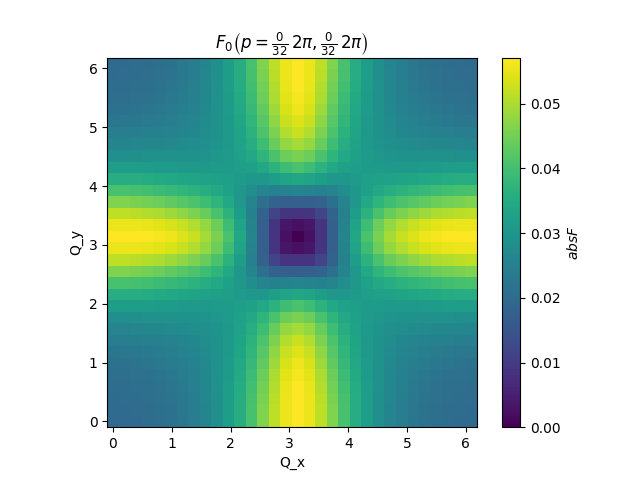

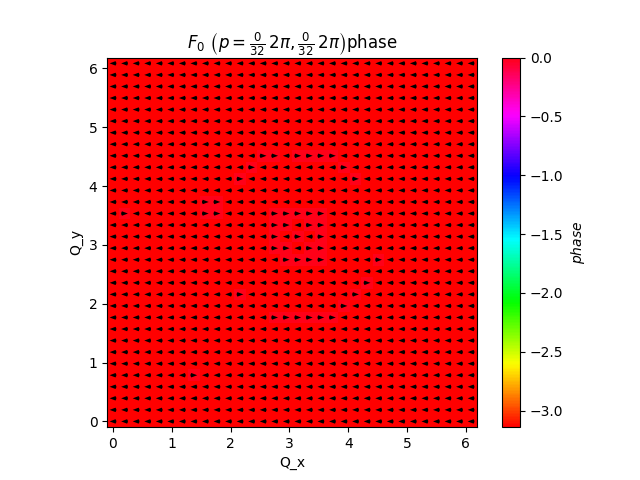

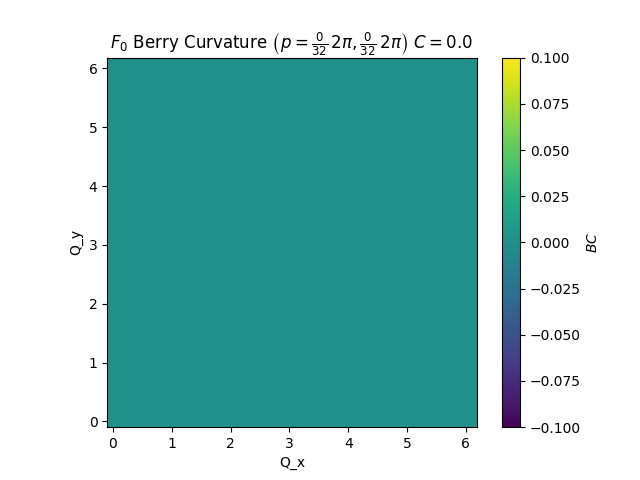

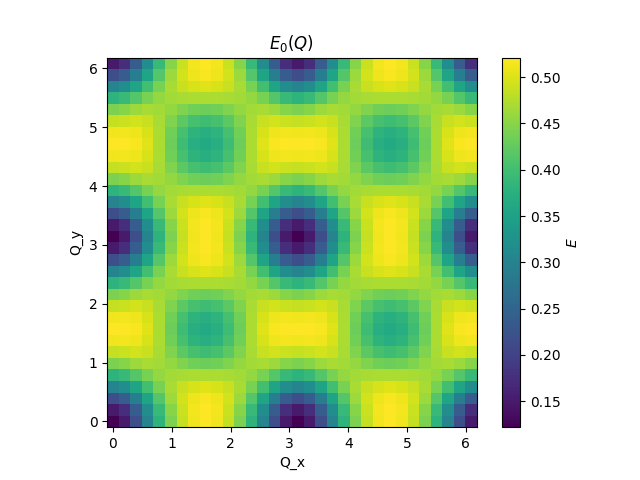

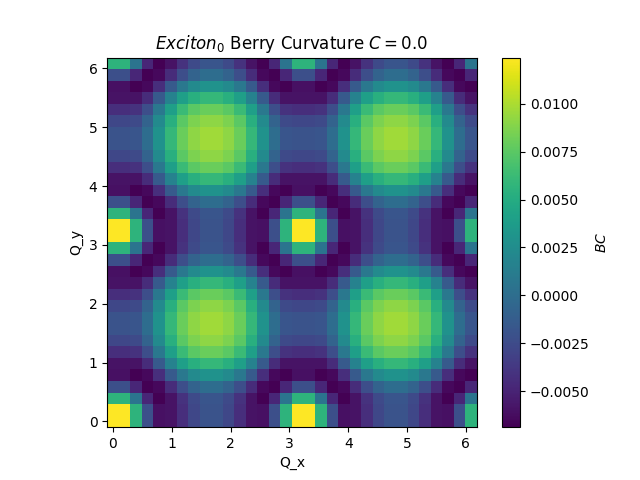

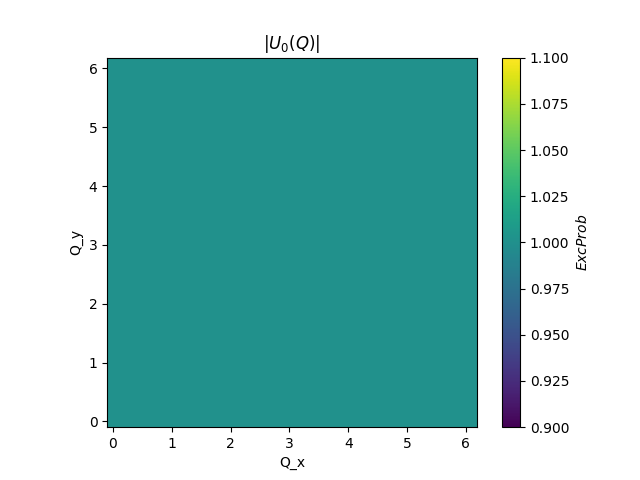

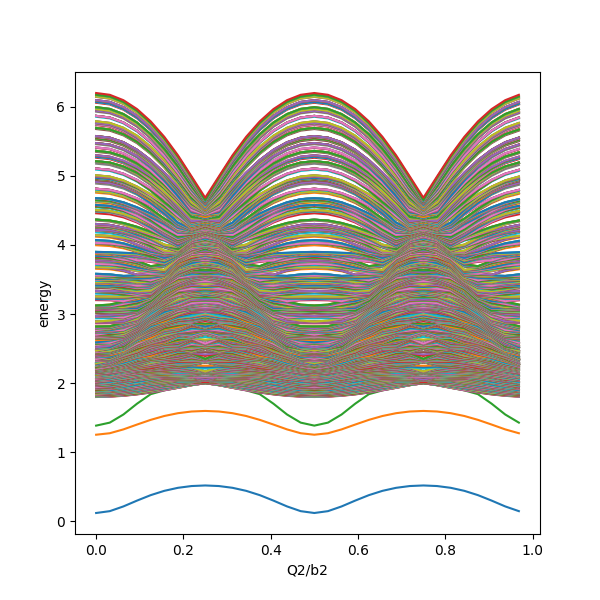

In [154]:
#Local_Tests\Data\2026-03-13_11-35-05-\2026-03-13_11-35-05
folder_name = r"2026-05-05_11-38-53"
LoadAndProcess("Data",folder_name,p_ind=(0,0))

### Single Graph

In [ ]:
def LoadGraphSingle(parent_folder,folder_name,case,band = None, p_ind=(0,0),out_folder=None):
    #from case get the naming convention for the desired data, from case we can also do the relevant manipulations to data.
    load_folder = f"{parent_folder}/{folder_name}"
    if out_folder == None:
        out_folder=load_folder
    configfile = os.path.join(load_folder, "config.yml")
    cfg = GetConfig(configfile)
    nk = cfg["Nk"]
    ltype = cfg["hamiltonian"]["lattice"]
    C=None
    if case in (GraphProtocol.AbsF2D,GraphProtocol.AbsF3D,GraphProtocol.FBC,GraphProtocol.FQuiver):
        Fnfile = os.path.join(load_folder, f"F[{band}].npy")
        Fn = np.load(Fnfile, mmap_mode='r')
        Fn_p = Fn[:,:,p_ind[0],p_ind[1]]
        #Fn_p= FpFromFk(Fn,p_ind,ltype)
        if case in (GraphProtocol.AbsF2D,GraphProtocol.AbsF3D):
            data = np.abs(Fn_p)
        elif case is GraphProtocol.FQuiver:
            data = np.angle(Fn_p)
        elif case is GraphProtocol.FBC:
            data,FC = GetBerryCurvature1band(Fn_p,ltype)
            C = np.round(FC,3)
        else:
            raise ValueError(f"how did I get here? {case}")
    elif case in (GraphProtocol.ExcE2D, GraphProtocol.EQ3D):
        eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
        eQ = np.load(eQfile, mmap_mode='r')
        data = eQ[:,:,band]
    elif case in (GraphProtocol.ExcProb2D,GraphProtocol.ExcProb3D):
        Uprobfilename = os.path.join(load_folder,f"U[{band}]_Prob.npy")
        data=np.load(Uprobfilename)
    elif case is GraphProtocol.ExcBC:
        prefix = os.path.join(load_folder, f"U[{band}]BC_C_")
        pattern = glob.escape(prefix) + "*.npy"   # <-- key fix
        UBCfiles = glob.glob(pattern)
        if not UBCfiles:
            raise FileNotFoundError(f"No matching file {pattern}")
        UBCfilename = UBCfiles[0]
        # extract C from filename
        m = re.search(r"BC_C_(.+)\.npy$", os.path.basename(UBCfilename))
        if not m:
            raise ValueError(f"Couldn't parse C from: {UBCfilename}")
        UnC = complex(m.group(1))   # works for real or complex strings
        C = round(UnC.real, 3)
        data = np.load(UBCfilename)
    elif case is GraphProtocol.ExcBandQx:
        #temp
        eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
        eQ = np.load(eQfile, mmap_mode='r')
        GraphQxConst(eQ,load_folder,cfg)
        return
    else:
        raise ValueError(f"{case} case not configured")
    GraphFromConfig(data,cfg,case,out_folder,band,p_ind,C=C)

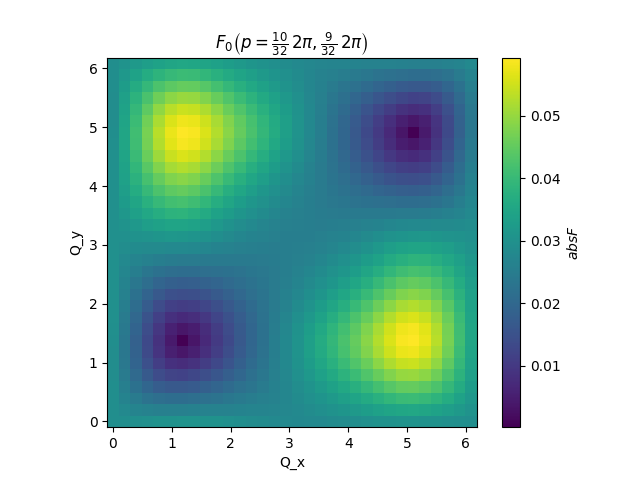

In [158]:
folder_name = r"2026-05-05_11-38-53"
LoadGraphSingle("Data", folder_name,GraphProtocol.AbsF2D,band = 0 , 
                        p_ind = (10,9),out_folder = f"Data/{folder_name}")

## Process Multi

### F all ps for video

In [ ]:
folder_name = r"2026-04-01_15-34-20"
#LoadGraphSingle("Data", folder_name,GraphProtocol.ExcBandQx,band = 0 , 
#                        p_ind = (0,0),out_folder = f"Data/{folder_name}/Test")
for px in range(32):
    for py in range(32):
        LoadGraphSingle("Data", folder_name,GraphProtocol.AbsF2D,band = 0 , 
                        p_ind = (px,py),out_folder = f"Data/{folder_name}/F_all_ps")

### create graphs for all unlisted folders

In [ ]:
parent_folder = "Data"
unprocessed = find_missing_folders(parent_folder)
for folder_name in unprocessed:
    load_and_process(parent_folder,folder_name)
list_subfolders(parent_folder)

In [ ]:
def list_subfolders(parent_folder):
    output_file = os.path.join(parent_folder, "folders.txt")

    with open(output_file, "w") as f:
        for entry in os.listdir(parent_folder):
            full_path = os.path.join(parent_folder, entry)

            if os.path.isdir(full_path):
                f.write(entry + "\n")

    print(f"Folder names written to: {output_file}")
    
def find_missing_folders(parent_folder):
    parent_folder = os.path.abspath(parent_folder)
    folders_file = os.path.join(parent_folder, "folders.txt")

    # ---- Read folders.txt ----
    if not os.path.isfile(folders_file):
        raise FileNotFoundError(f"{folders_file} not found.")

    with open(folders_file, "r") as f:
        listed_folders = {line.strip() for line in f if line.strip()}

    # ---- Actual subfolders in directory ----
    actual_folders = {
        name for name in os.listdir(parent_folder)
        if os.path.isdir(os.path.join(parent_folder, name))
    }

    # ---- Find those NOT listed ----
    missing = sorted(actual_folders - listed_folders)

    return missing

### Move graphs from data folder to Images/Exploration

In [ ]:
import shutil
import re

def copy_bc_png(src_folder, dst_folder, new_filename):
    # Ensure the output filename ends with .png later
    new_filename = new_filename.rstrip(".png")

    # Regex to match BC C=(real+imagj).png
    pattern = re.compile(r"^BC C=\(([-+]?\d*\.?\d+)[-+]\d*\.?\d+j\)\.png$")

    # Absolute paths
    src_folder = os.path.abspath(src_folder)
    dst_folder = os.path.abspath(dst_folder)
    os.makedirs(dst_folder, exist_ok=True)

    # Search for matching file
    for filename in os.listdir(src_folder):
        match = pattern.match(filename)
        if match:
            real_part = match.group(1)  # Extract real number as string

            # Create output filename
            final_name = f"{new_filename}_C={real_part}.png"

            src_path = os.path.join(src_folder, filename)
            dst_path = os.path.join(dst_folder, final_name)

            shutil.copy2(src_path, dst_path)
            return final_name  # Success

    return None  # No matching file found

def copy_energy_png(src_folder, dst_folder, new_filename):
    # Ensure ".png" extension on new filename
    if not new_filename.lower().endswith(".png"):
        new_filename += ".png"

    # Absolute paths
    src_folder = os.path.abspath(src_folder)
    dst_folder = os.path.abspath(dst_folder)

    # Create destination folder if needed
    os.makedirs(dst_folder, exist_ok=True)

    # Look for the first Energy*.png file
    for filename in os.listdir(src_folder):
        if filename.startswith("Energy") and filename.endswith(".png"):
            src_path = os.path.join(src_folder, filename)
            dst_path = os.path.join(dst_folder, new_filename)

            shutil.copy2(src_path, dst_path)
            return new_filename  # success

    return None  # no file found

# misc

In [ ]:
def add_title_to_image(image_path, title, font_size=40, padding=10):
    image = Image.open(image_path)
    width, height = image.size

    # Height for the title space, which includes padding
    title_height = font_size + 2 * padding

    # Create a new image with extra space for the title (white background)
    new_image = Image.new("RGB", (width, height + title_height), "white")

    # Paste the original image below the title space
    new_image.paste(image, (0, title_height))  # (0, title_height) places the image below the title area

    # Draw the title
    draw = ImageDraw.Draw(new_image)

    try:
        # Attempt to load a font, otherwise fallback to default
        font = ImageFont.truetype("arial.ttf", font_size)
    except IOError:
        font = ImageFont.load_default()  # Fallback to default if Arial is missing

    # Use textbbox() to get text size
    bbox = draw.textbbox((0, 0), title, font=font)
    text_width = bbox[2] - bbox[0]
    text_height = bbox[3] - bbox[1]

    # Center the text within the title space
    text_x = (width - text_width) // 2  # Horizontally center
    text_y = (title_height - text_height) // 2  # Vertically center with padding

    # Draw the title in black for visibility
    draw.text((text_x, text_y), title, fill="black", font=font)

    return new_image

In [ ]:
from pathlib import Path
import os
import re
from PIL import Image

def MakeGifs(source_path):
    # Define input and output folders
    image_folder = Path("Images") / source_path
    output_folder = Path("Gifs") / source_path
    os.makedirs(output_folder, exist_ok=True)

    if not image_folder.is_dir():
        print("Image folder does not exist:", image_folder)
        return

    # Get all PNG files
    png_files = [p for p in image_folder.glob("*.png") if p.is_file()]
    if not png_files:
        print("No PNG images found in", image_folder)
        return

    # Patterns:
    #  1) U=#.png
    simple_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)\.png$")
    #  2) U=#_C=#.png
    bc_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)_C=([+-]?\d*\.?\d+)\.png$")
    #  3) F_0_p{i}_{j}.png
    f_pattern = re.compile(r"^F_0_p(\d+)_(\d+)\.png$")

    simple_files = []  # {"u_val", "u_str", "path"}
    bc_files = []      # {"u_val", "u_str", "c_str", "path"}
    f_files = []       # {"i", "j", "path"}

    for path in png_files:
        fname = path.name

        m_f = f_pattern.match(fname)
        if m_f:
            i, j = int(m_f.group(1)), int(m_f.group(2))

            # Keep only i,j in range(64)
            if 0 <= i < 64 and 0 <= j < 64:
                f_files.append({"i": i, "j": j, "path": path})
            else:
                print(f"Skipping {fname}: i or j out of range(64)")
            continue

        m_bc = bc_pattern.match(fname)
        if m_bc:
            u_str, c_str = m_bc.group(1), m_bc.group(2)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            bc_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "c_str": c_str,
                "path": path
            })
            continue

        m_simple = simple_pattern.match(fname)
        if m_simple:
            u_str = m_simple.group(1)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            simple_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "path": path
            })
        else:
            print("Skipping file with unexpected name pattern:", fname)

    # Decide which mode we're in
    if f_files:
        mode = "F"
        files = sorted(f_files, key=lambda d: (d["i"], d["j"]))  # loop over i, then j
    elif bc_files:
        mode = "BC"
        files = sorted(bc_files, key=lambda d: d["u_val"])
    elif simple_files:
        mode = "simple"
        files = sorted(simple_files, key=lambda d: d["u_val"])
    else:
        print("No files matched the expected patterns.")
        return

    processed_images = []
    for item in files:
        img_path = item["path"]

        if mode == "F":
            img = Image.open(img_path)
        elif mode == "BC":
            title = f"C={item['c_str']}"
            img = add_title_to_image(img_path, title)
        else:
            title = f"U={item['u_str']}"
            img = add_title_to_image(img_path, title)

        processed_images.append(img)

    if not processed_images:
        print("No images processed, GIF not created.")
        return

    # Output GIF filename depending on mode
    if mode == "F":
        gif_name = "F_0_p.gif"
    elif mode == "BC":
        gif_name = "BC.gif"
    else:
        gif_name = "Energy_Bands.gif"

    output_gif_path = output_folder / gif_name

    processed_images[0].save(
        output_gif_path,
        save_all=True,
        append_images=processed_images[1:],
        duration=100,
        loop=0,
    )

    print("GIF saved as:", output_gif_path)

In [ ]:
from pathlib import Path
import os
import re
from PIL import Image
import imageio.v2 as imageio
import numpy as np


def MakeVideos(source_path, fps=20):
    # Define input and output folders
    image_folder = Path("Images") / source_path
    output_folder = Path("Videos") / source_path
    os.makedirs(output_folder, exist_ok=True)

    if not image_folder.is_dir():
        print("Image folder does not exist:", image_folder)
        return

    # Get all PNG files
    png_files = [p for p in image_folder.glob("*.png") if p.is_file()]
    if not png_files:
        print("No PNG images found in", image_folder)
        return

    # Patterns
    simple_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)\.png$")
    bc_pattern = re.compile(r"^U=([+-]?\d*\.?\d+)_C=([+-]?\d*\.?\d+)\.png$")
    f_pattern = re.compile(r"^F_0_p(\d+)_(\d+)\.png$")

    simple_files = []
    bc_files = []
    f_files = []

    for path in png_files:
        fname = path.name

        m_f = f_pattern.match(fname)
        if m_f:
            i, j = int(m_f.group(1)), int(m_f.group(2))
            if 0 <= i < 64 and 0 <= j < 64:
                f_files.append({"i": i, "j": j, "path": path})
            else:
                print(f"Skipping {fname}: i or j out of range(64)")
            continue

        m_bc = bc_pattern.match(fname)
        if m_bc:
            u_str, c_str = m_bc.group(1), m_bc.group(2)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            bc_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "c_str": c_str,
                "path": path
            })
            continue

        m_simple = simple_pattern.match(fname)
        if m_simple:
            u_str = m_simple.group(1)
            try:
                u_val = float(u_str)
            except ValueError:
                print(f"Could not parse U value in {fname}, skipping.")
                continue
            simple_files.append({
                "u_val": u_val,
                "u_str": u_str,
                "path": path
            })
        else:
            print("Skipping file with unexpected name pattern:", fname)

    # Decide mode
    if f_files:
        mode = "F"
        files = sorted(f_files, key=lambda d: (d["i"], d["j"]))
    elif bc_files:
        mode = "BC"
        files = sorted(bc_files, key=lambda d: d["u_val"])
    elif simple_files:
        mode = "simple"
        files = sorted(simple_files, key=lambda d: d["u_val"])
    else:
        print("No files matched expected patterns.")
        return

    frames = []

    for item in files:
        img_path = item["path"]

        if mode == "F":
            img = Image.open(img_path)
        elif mode == "BC":
            title = f"C={item['c_str']}"
            img = add_title_to_image(img_path, title)
        else:
            title = f"U={item['u_str']}"
            img = add_title_to_image(img_path, title)

        frames.append(np.array(img))

    if not frames:
        print("No frames collected, video not created.")
        return

    # Output filename
    if mode == "F":
        video_name = "F_0_p.mp4"
    elif mode == "BC":
        video_name = "BC.mp4"
    else:
        video_name = "Energy_Bands.mp4"

    output_video_path = output_folder / video_name

    imageio.mimsave(
        output_video_path,
        frames,
        fps=fps,
        codec="libx264",
        quality=8
    )

    print("Video saved as:", output_video_path)

In [ ]:
from pathlib import Path
from PIL import Image

def resize_pngs_in_folder(folder_path, size=(384, 464), overwrite=True):
    folder = Path(folder_path)

    for png_file in folder.glob("*.png"):
        try:
            with Image.open(png_file) as img:
                img = img.convert("RGB")  # ensure consistent format
                resized = img.resize(size, Image.LANCZOS)

                if overwrite:
                    resized.save(png_file)
                else:
                    new_path = png_file.with_name(png_file.stem + "_resized.png")
                    resized.save(new_path)

        except Exception as e:
            print(f"Skipping {png_file}: {e}")

In [ ]:
source_path= Path(r"Haldane\F_all_p_U5(1,1)")
image_folder = Path("Images") / source_path
resize_pngs_in_folder(image_folder)

In [ ]:
source_path= Path(r"Haldane\F_all_p_U5(1,1)")
#rs = ["0","1%32","1%16","1%8","1%4","1%2","1","2","4","8","16","32","inf"]
MakeVideos(source_path)

In [ ]:
def combine_gifs_side_by_side(gif1_path, gif2_path, output_path):
    gif1 = Image.open(gif1_path)
    gif2 = Image.open(gif2_path)

    # Convert all frames to RGB to avoid palette issues
    frames1 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif1)]
    frames2 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif2)]

    if len(frames1) != len(frames2):
        raise ValueError("GIFs must have the same number of frames")

    combined_frames = []

    for f1, f2 in zip(frames1, frames2):
        # Resize to match height
        if f1.height != f2.height:
            new_height = min(f1.height, f2.height)
            f1 = f1.resize(
                (int(f1.width * new_height / f1.height), new_height),
                Image.Resampling.LANCZOS
            )
            f2 = f2.resize(
                (int(f2.width * new_height / f2.height), new_height),
                Image.Resampling.LANCZOS
            )

        # Combine side by side
        combined_width = f1.width + f2.width
        combined = Image.new("RGB", (combined_width, f1.height))
        combined.paste(f1, (0, 0))
        combined.paste(f2, (f1.width, 0))
        combined_frames.append(combined)

    # Save as palette-based GIF ("P" mode)
    combined_frames = [frame.convert("P", palette=Image.ADAPTIVE) for frame in combined_frames]

    combined_frames[0].save(
        output_path,
        save_all=True,
        append_images=combined_frames[1:],
        duration=gif1.info.get("duration", 100),
        loop=0,
        disposal=2
    )

# Example usage
path1 = "Gifs/Explorations/Haldane Vd near 10/Energy/Energy_Bands.gif"
path2 = "Gifs/Explorations/Haldane Vd near 10/BC/BC.gif"
destination_path = "Showtime/Roni&Tobias meeting nov 2025/Haldane_Vd10_side_by_side.gif"
combine_gifs_side_by_side(
    Path(path1),
    Path(path2),
    Path(destination_path)
)


In [ ]:
from pathlib import Path
import os
import re
from PIL import Image, ImageOps, ImageDraw, ImageFont
import imageio.v2 as imageio
import numpy as np


def combine_images_side_by_side(left_img_path, right_img_path, left_label=None, right_label=None, pad=10):
    left_img = Image.open(left_img_path).convert("RGB")
    right_img = Image.open(right_img_path).convert("RGB")

    # Make both images the same height
    target_height = max(left_img.height, right_img.height)

    def resize_to_height(img, height):
        if img.height == height:
            return img
        new_width = int(img.width * (height / img.height))
        return img.resize((new_width, height), Image.Resampling.LANCZOS)

    left_img = resize_to_height(left_img, target_height)
    right_img = resize_to_height(right_img, target_height)

    # Optional labels area
    label_height = 30 if (left_label or right_label) else 0

    total_width = left_img.width + right_img.width + pad
    total_height = target_height + label_height

    canvas = Image.new("RGB", (total_width, total_height), "white")
    draw = ImageDraw.Draw(canvas)

    # Paste images
    y_offset = label_height
    canvas.paste(left_img, (0, y_offset))
    canvas.paste(right_img, (left_img.width + pad, y_offset))

    # Draw labels
    if left_label or right_label:
        font = ImageFont.load_default()
        if left_label:
            draw.text((10, 8), left_label, fill="black", font=font)
        if right_label:
            draw.text((left_img.width + pad + 10, 8), right_label, fill="black", font=font)

    return canvas


def MakeSideBySideVideoTwoFolders(source_folder, left, right, output_name="this&that.mp4", fps=20):
    # Define folders
    source = Path("Images") / source_folder
    left_folder = source / left
    right_folder = source / right
    output_folder = Path("Videos") / source_folder
    os.makedirs(output_folder, exist_ok=True)

    if not left_folder.is_dir():
        print("Left folder does not exist:", left_folder)
        return

    if not right_folder.is_dir():
        print("Right folder does not exist:", right_folder)
        return

    # Patterns
    left_pattern = re.compile(r"^F_0_p(\d+)_(\d+)\.png$")
    right_pattern = re.compile(r"^Overlap_p(\d+)_(\d+)\.png$")

    left_files = {}
    right_files = {}

    # Scan left folder
    for path in left_folder.glob("*.png"):
        m = left_pattern.match(path.name)
        if m:
            i, j = int(m.group(1)), int(m.group(2))
            if 0 <= i < 64 and 0 <= j < 64:
                left_files[(i, j)] = path

    # Scan right folder
    for path in right_folder.glob("*.png"):
        m = right_pattern.match(path.name)
        if m:
            i, j = int(m.group(1)), int(m.group(2))
            if 0 <= i < 64 and 0 <= j < 64:
                right_files[(i, j)] = path

    # Match pairs
    common_keys = sorted(set(left_files) & set(right_files))

    if not common_keys:
        print("No matching pairs found between folders.")
        return

    frames = []

    for i, j in common_keys:
        left_path = left_files[(i, j)]
        right_path = right_files[(i, j)]

        combined = combine_images_side_by_side(
            left_path,
            right_path,
            left_label=f"F_0_p{i}_{j}",
            right_label=f"Overlaps_p{i}_{j}"
        )

        frames.append(np.array(combined))

    if not frames:
        print("No frames collected, video not created.")
        return

    output_video_path = output_folder / output_name

    imageio.mimsave(
        output_video_path,
        frames,
        fps=fps,
        codec="libx264",
        quality=8
    )

    print("Video saved as:", output_video_path)

In [ ]:
MakeSideBySideVideoTwoFolders(
    source_folder = "QWZ/U5(-1,0)extended",
    left="F_all_ps",
    right="overlaps",
    fps=30
)

## Tests

### Wavefunction overlaps

In [ ]:
def GetcvOverlap(ni_wf, gx, c=1, v=0, p_ind=(0,0), ltype = 'square'):
    #for the exchange case F(p,Q) ~ <u^c(p+Q/2)|u^v(p-Q/2)>C(Q)
    nk = np.shape(ni_wf)[0]
    vals = np.zeros((nk,nk), dtype=complex)
    Kp = (p_ind[0],p_ind[1],0,0)
    #Nk = NQ for extended zone
    for Qx in range(nk):
        for Qy in range(nk):
            Kc = PBCAddInd(Kp,(Qx,Qy),nk,ltype)
            Kv = PBCAddInd(Kp,(-Qx,-Qy),nk,ltype)
            uc = u_ext(ni_wf,gx,Kc,c)
            uv = u_ext(ni_wf,gx,Kv,v)
            val = np.vdot(uc,uv)
            vals[Qx,Qy] = val
    return vals
parent_folder = "Data"
folder_name = "2026-04-01_15-34-20"
load_folder = f"{parent_folder}/{folder_name}"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(f"{configfile}")
ni_eval, ni_wf = SolveBzNoninteracting(cfg)
gx  = SeamPhaseGx(ni_wf)
#for px in range(32):
#    for py in range(32):
p = (0,0)
overlaps = GetcvOverlap(ni_wf,gx,c=0,v=0,p_ind=p)
GraphFromConfig(np.abs(overlaps)/np.linalg.norm(overlaps),cfg,GraphProtocol.Test,f"{load_folder}/overlaps",p_ind=p)

In [ ]:
explorer = InteractiveWindingExplorer(
    overlaps,
    radii=[1, 2, 3, 4, 5],
    search_radius=6,
    p=p
    
)

plt.show()

### Seprable F solution
In the seperable BSE case, where the kernal is like $\lambda S_p(Q)S_{p'}^*(Q')$, for example the exchange case where $S_p(Q) = \langle u_c(p+Q/2)|u_v(p-Q/2)\rangle$ we can find explicit solution for the F's in the form of $|F_p(Q)|^2 = \frac{|S_p(Q)|^2}{|E_{exc}(Q)-\Delta_{p}(Q)|^2}\left(\sum_{p'}\frac{|S_{p'}(Q)|^2}{|E_{exc}(Q)-\Delta_{p'}(Q)|^2}\right)^{-1}=\frac{|S_p(Q)|^2}{|\mathcal{E}(Q)|^2} C(Q)$

Here $\Delta_p =  \epsilon_{(\vec{p} + \vec{Q/2}) c} - \epsilon_{(\vec{p}-\vec{Q/2}) v}$

In [ ]:
def AnalyticSeperableF(ni_wf, ni_evals, gx, exc_energy,Q_ind,p_ind,cfg):
    """
    input: ni_wf[kx,ky,n_orb,n_band], ni_evals[kx,ky,n_band], exc_energy [Qx,Qy] (band is pre-selected), 
    Q_ind touple (Qx,Qy), p_ind touple (px,py).
    assumptions: grid sew, range (-pi,pi), S exchange construction
    output: abs(F^2) for single Q and p
    """
    NQ = cfg["NQ"]
    Np = cfg["Nk"]
    ltype = cfg["hamiltonian"]["lattice"]
    c = cfg["c_band"]
    v = cfg["v_band"]
    range_handle = cfg["Range"]
    (Qx,Qy) = Q_ind
    (px,py) = p_ind
    if range_handle == "center":
        qxi = Qx - NQ//2
        qyi = Qy - NQ//2
    elif range_handle == "foreward":
        qxi = Qx
        qyi = Qx
    Kp = (px,py,0,0)
    Kv = PBCAddInd(Kp,(-qxi,-qyi),Np,ltype)
    Kc = PBCAddInd(Kp,(qxi,qyi),Np,ltype)
    uc = u_ext(ni_wf,gx,Kc,c)
    uv = u_ext(ni_wf,gx,Kv,v)
    S = np.vdot(uc,uv)
    S2 = np.vdot(S,S)
    E = exc_energy[Qx,Qy] - (ni_eval[Kc[0],Kc[1],c]-ni_eval[Kv[0],Kv[1],v])
    E2 = np.vdot(E,E)
    val = 0
    for pxp in range(Np):
        for pyp in range(Np):
            Kpp = (pxp,pyp,0,0)
            Kvp = PBCAddInd(Kpp,(-qxi,-qyi),Np,ltype)
            Kcp = PBCAddInd(Kpp,(qxi,qyi),Np,ltype)
            ucp = u_ext(ni_wf,gx,Kcp,c)
            uvp = u_ext(ni_wf,gx,Kvp,v)
            Sp = np.vdot(ucp,uvp)
            S2p = np.vdot(Sp,Sp)
            Ep = exc_energy[Qx,Qy] - (ni_eval[Kcp[0],Kcp[1],c]-ni_eval[Kvp[0],Kvp[1],v])
            E2p = np.vdot(Ep,Ep)
            val+=S2p/E2p
    C= np.pow(val,-1)
    F2 = (S2/E2)*C
    return F2

In [ ]:
band = 0
parent_folder = "Data"
folder_name = "2026-03-29_16-25-31"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/seperable_test"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(f"{configfile}")
eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
eQ = np.load(eQfile, mmap_mode='r')
NQ = cfg["NQ"]
Nk = cfg["Nk"]
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
gx = SeamPhaseGx(ni_wf)
exc_evals = eQ[:,:,band]
Fn_grid = np.zeros((NQ,NQ),dtype = float)
for px in range(Nk):
    for py in range(Nk):
        p=(px,py)
        for Qx in range(NQ):
            for Qy in range(NQ):
                Fn_grid[Qx,Qy] = np.sqrt(AnalyticSeperableF(ni_wf, ni_evals, gx, exc_evals,(Qx,Qy),p,cfg))
        GraphFromConfig(Fn_grid,cfg,GraphProtocol.Test,out_folder,band,p,C=None)

### Open boundary Berry curvature
for dirac model and other continuum tests

In [ ]:
def GetBCOpenPBC(u):
    N = u.shape[0] #assumes u.shape[N,N,:]
    link_x=np.zeros([N-1,N-1], dtype="complex")
    link_y=np.zeros([N-1,N-1], dtype="complex")
    BC=np.zeros([N-2,N-2], dtype="complex")
    for i in range(N-1):
        for j in range(N-1):
            iR,jR = (i+1,j)
            iU,jU = (i,j+1)
            #link_x[i,j]=(u[iL,jL,:].conj().T @ u[i,j,:])/(np.abs(u[iL,jL,:].conj().T @ u[i,j,:]))
            #link_y[i,j]=(u[iD,jD,:].conj().T @ u[i,j,:])/(np.abs(u[iD,jD,:].conj().T @ u[i,j,:]))
            num = np.vdot(u[i, j], u[iR, jR])
            link_x[i, j] = num / np.abs(num)
            num = np.vdot(u[i, j], u[iU, jU])
            link_y[i, j] = num / np.abs(num)
    for i in range(N-2):
        for j in range(N-2):
            iR,jR = (i+1,j)
            iU,jU = (i,j+1)
            val = np.imag(np.log(link_x[i,j]))
            val += np.imag(np.log(link_y[iR,jR]))
            val -= np.imag(np.log((link_x[iU,jU])))
            val -= np.imag(np.log(link_y[i,j]))
            #commented code to erase undefined points at band crossings
            #if not math.isnan(val):
            BC[i,j] = val
            #else:
                #BC[i,j]=BC[i,j-1]
    C=np.sum(BC)/(2*np.pi)
    return BC,C

In [ ]:
Qxlist = np.linspace(-np.pi,np.pi,32)
Qylist = np.linspace(-np.pi,np.pi,32)
dQx = Qxlist[1]
dQy = Qylist[1]
arr = (Qxlist[:, None]) + (1j * Qylist[None, :])

In [ ]:
cfg = GetConfig("configqwz.yml")
cfg["Qxlist"] = Qxlist
cfg["Qylist"] = Qylist
BCtest,Ctest = GetBCOpenPBC(arr)
GraphFromConfig(np.real(BCtest),cfg,GraphProtocol.Test,"Images")
print(Ctest)

### Single particle case
$F(p,Q) = \delta_{p,p'}(Q)$ meaning $\psi = \sum_pF(p,Q)u^c(p+Q/2)u^v(p-Q/2)^*=u^c(p'+Q/2)u^v(p'-Q/2)^*$

In [ ]:
import ExcitonWF
band = 0
p_prime = (0,0)
parent_folder = "Data"
folder_name = "2026-03-23_13-57-26"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(f"{configfile}")
Fn_file = os.path.join(load_folder, f"F[{band}].npy")
Fn = np.load(Fn_file, mmap_mode='r')
NQ = cfg["NQ"]
v = cfg["v_band"]
c = cfg["c_band"]
ni_evals, ni_wf = SolveBzNoninteracting(cfg)
gx = SeamPhaseGx(ni_wf)
range_handle = cfg["Range"]
Fn_delta = np.zeros_like(Fn)
Fn_delta[:,:,p_prime[0],p_prime[1]] = 1.0
UnBC, Cn = ExcitonWF.GetExcitonBC(Fn_delta, ni_wf, v, c, cfg.get("hamiltonian").get("lattice"), gx,range_handle)
GraphFromConfig(UnBC,cfg,GraphProtocol.ExcBC,out_folder,band,p_prime,C=Cn)

### Vorticity of single zero

#### Carolina ver

In [ ]:
def find_min_points(F, rtol=0.0, atol=0.0, top_k=None):

    A = np.abs(F)
    m = A.min()
    
    thresh = m + atol + rtol*m
    pts = np.argwhere(A <= thresh)
    
    if top_k is not None:
        flat = A.ravel()
        k = min(int(top_k), flat.size)
        idx = np.argpartition(flat, k-1)[:k]
        pts_k = np.column_stack(np.unravel_index(idx, A.shape))
        # merge, unique
        pts = np.vstack([pts, pts_k])
        pts = np.unique(pts, axis=0)
    
    return m, pts, A
def summarize_points(A, pts):
    vals = A[pts[:,0], pts[:,1]]
    order = np.argsort(vals)
    pts = pts[order]
    vals = vals[order]
    return [(int(i), int(j), float(v)) for (i,j), v in zip(pts, vals)]

def plot_amp_with_all_plaquettes(F, logscale=False, cmap="viridis",
                                 grid_color="r", grid_lw=0.6,
                                 mark_min=True, min_rtol=0.0, min_atol=0.0):

    Nx, Ny = F.shape
    A = np.abs(F).astype(float)
    Z = np.log10(A + 1e-300) if logscale else A

    fig, ax = plt.subplots(figsize=(6,5))
    
    # cell edges at integer coordinates
    x = np.arange(Nx+1)
    y = np.arange(Ny+1)
    
    pm = ax.pcolormesh(x, y, Z.T, shading="auto", cmap=cmap)
    fig.colorbar(pm, ax=ax, label=("log10|F|" if logscale else "|F|"))
    
    # draw ALL plaquette boundaries
    ax.vlines(np.arange(Nx+1), 0, Ny, colors=grid_color, linewidth=grid_lw)
    ax.hlines(np.arange(Ny+1), 0, Nx, colors=grid_color, linewidth=grid_lw)
    
    # mark minima (all ties within tolerance)
    if mark_min:
        m = A.min()
        thresh = m + min_atol + min_rtol*m
        pts = np.argwhere(A <= thresh)
        # mark as points at lattice vertices (not cell centers)
        ax.scatter(pts[:,0], pts[:,1], s=40, facecolors="none",
                   edgecolors="w", linewidths=1.5)
        ax.set_title(f"|F| with all plaquettes; min={m:.3e}, count={len(pts)}")
    else:
        ax.set_title("|F| with all plaquettes")
    
    ax.set_xlim(0, Nx)
    ax.set_ylim(0, Ny)
    ax.set_aspect("equal")
    ax.set_xlabel("Qx index")
    ax.set_ylabel("Qy index")
    plt.tight_layout()
    return fig, ax

px0=5
py0=12

F00 = Exciton_F[:,:,px0,py0]

plot_amp_with_all_plaquettes(F00, logscale=False, grid_color="r", grid_lw=0.5,
                              mark_min=True, min_rtol=1e-3)
plt.show()

def wrap_angle(dphi):
    return (dphi + np.pi) % (2*np.pi) - np.pi

def square_loop_indices(N, i0, j0, r):
    pts = []

    # bottom edge: (i0-r .. i0+r-1, j0-r)
    for i in range(i0 - r, i0 + r):
        pts.append((i, j0 - r))
    # right edge: (i0+r, j0-r .. j0+r-1)
    for j in range(j0 - r, j0 + r):
        pts.append((i0 + r, j))
    # top edge: (i0+r .. i0-r+1, j0+r)
    for i in range(i0 + r, i0 - r, -1):
        pts.append((i, j0 + r))
    # left edge: (i0-r, j0+r .. j0-r+1)
    for j in range(j0 + r, j0 - r, -1):
        pts.append((i0 - r, j))
    # periodic wrap
    pts = [(i % N, j % N) for (i, j) in pts]
    return pts
def winding_around_vertex(
    f, i0, j0, amp_cut=1e-12, r_max=None, r_fixed=None,
    orientation="ccw", rel_cut=1e-6, require_safe=True
):

    N = f.shape[0]

def compute_on_radius(r):
    loop = square_loop_indices(N, i0, j0, r)

    if orientation.lower() == "cw":
        loop = loop[::-1]

    amps = np.array([abs(f[i, j]) for (i, j) in loop])
    scale = np.max(amps)

    # reject loops that pass too close to a zero
    if require_safe:
        if scale == 0:
            return None, None
        if np.any(amps < max(amp_cut, rel_cut * scale)):
            return None, None

    phases = np.array([np.angle(f[i, j]) for (i, j) in loop])
    dphis = wrap_angle(np.diff(np.r_[phases, phases[0]]))
    W = dphis.sum() / (2 * np.pi)
    return W, r

if r_fixed is not None:
    return compute_on_radius(r_fixed)

if r_max is None:
    r_max = N // 2 - 1

for r in range(1, r_max + 1):
    W, r_used = compute_on_radius(r)
    if W is not None:
        return W, r_used

return None, None


f_phys = Exciton_F[:, :, px0, py0] 

m, pts, A = find_min_points(f_phys, rtol=1e-3, atol=0.0)
print(summarize_points(A, pts)[:20])

winding_each_zero = []
total_winding_zeros = 0.0
for (i,j) in enumerate(pts):
    Wccw, r_used = winding_around_vertex(f_phys, j[0], j[1], amp_cut=1e-12, orientation="ccw")
    print(r_used)
    winding_each_zero.append((j,Wccw))
    total_winding_zeros += Wccw

print("Winding from each zero:" , winding_each_zero)
print("Total winding from zeros of the F:" , total_winding_zeros)



In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def find_min_points(F, rtol=0.0, atol=0.0, top_k=None):
    A = np.abs(F)
    m = A.min()

    thresh = m + atol + rtol * m
    pts = np.argwhere(A <= thresh)

    if top_k is not None:
        flat = A.ravel()
        k = min(int(top_k), flat.size)
        if k > 0:
            idx = np.argpartition(flat, k - 1)[:k]
            pts_k = np.column_stack(np.unravel_index(idx, A.shape))
            pts = np.vstack([pts, pts_k])
            pts = np.unique(pts, axis=0)

    return m, pts, A


def summarize_points(A, pts):
    vals = A[pts[:, 0], pts[:, 1]]
    order = np.argsort(vals)
    pts = pts[order]
    vals = vals[order]
    return [(int(i), int(j), float(v)) for (i, j), v in zip(pts, vals)]


def plot_amp_with_all_plaquettes(
    F,
    logscale=False,
    cmap="viridis",
    grid_color="r",
    grid_lw=0.6,
    mark_min=True,
    min_rtol=0.0,
    min_atol=0.0,
):
    Nx, Ny = F.shape
    A = np.abs(F).astype(float)
    Z = np.log10(A + 1e-300) if logscale else A

    fig, ax = plt.subplots(figsize=(6, 5))

    x = np.arange(Nx + 1)
    y = np.arange(Ny + 1)

    pm = ax.pcolormesh(x, y, Z.T, shading="auto", cmap=cmap)
    fig.colorbar(pm, ax=ax, label=("log10|F|" if logscale else "|F|"))

    ax.vlines(np.arange(Nx + 1), 0, Ny, colors=grid_color, linewidth=grid_lw)
    ax.hlines(np.arange(Ny + 1), 0, Nx, colors=grid_color, linewidth=grid_lw)

    if mark_min:
        m = A.min()
        thresh = m + min_atol + min_rtol * m
        pts = np.argwhere(A <= thresh)
        ax.scatter(
            pts[:, 0],
            pts[:, 1],
            s=40,
            facecolors="none",
            edgecolors="w",
            linewidths=1.5,
        )
        ax.set_title(f"|F| with all plaquettes; min={m:.3e}, count={len(pts)}")
    else:
        ax.set_title("|F| with all plaquettes")

    ax.set_xlim(0, Nx)
    ax.set_ylim(0, Ny)
    ax.set_aspect("equal")
    ax.set_xlabel("Qx index")
    ax.set_ylabel("Qy index")
    plt.tight_layout()
    return fig, ax


def wrap_angle(dphi):
    return (dphi + np.pi) % (2 * np.pi) - np.pi


def square_loop_indices(N, i0, j0, r):
    pts = []

    # bottom edge
    for i in range(i0 - r, i0 + r):
        pts.append((i, j0 - r))

    # right edge
    for j in range(j0 - r, j0 + r):
        pts.append((i0 + r, j))

    # top edge
    for i in range(i0 + r, i0 - r, -1):
        pts.append((i, j0 + r))

    # left edge
    for j in range(j0 + r, j0 - r, -1):
        pts.append((i0 - r, j))

    pts = [(i % N, j % N) for (i, j) in pts]
    return pts


def winding_around_vertex(
    f,
    i0,
    j0,
    amp_cut=1e-12,
    r_max=None,
    r_fixed=None,
    orientation="ccw",
    rel_cut=1e-6,
    require_safe=True,
):
    N = f.shape[0]

    def compute_on_radius(r):
        loop = square_loop_indices(N, i0, j0, r)

        if orientation.lower() == "cw":
            loop = loop[::-1]

        amps = np.array([abs(f[i, j]) for (i, j) in loop])
        scale = np.max(amps)

        # reject loops that pass too close to a zero
        if require_safe:
            if scale == 0:
                return None, None
            if np.any(amps < max(amp_cut, rel_cut * scale)):
                return None, None

        phases = np.array([np.angle(f[i, j]) for (i, j) in loop])
        dphis = wrap_angle(np.diff(np.r_[phases, phases[0]]))
        W = dphis.sum() / (2 * np.pi)
        return W, r

    if r_fixed is not None:
        return compute_on_radius(r_fixed)

    if r_max is None:
        r_max = N // 2 - 1

    for r in range(1, r_max + 1):
        W, r_used = compute_on_radius(r)
        if W is not None:
            return W, r_used

    return None, None

In [ ]:
px0 = 2
py0 = 8
parent_folder = "Data"
folder_name = "2026-04-27_15-39-07"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
Fn_file = os.path.join(load_folder, f"F[0].npy")
Fn = np.load(Fn_file, mmap_mode='r')
f_phys = Fn[:, :, px0, py0]

plot_amp_with_all_plaquettes(
    f_phys,
    logscale=False,
    grid_color="r",
    grid_lw=0.5,
    mark_min=True,
    min_rtol=1e-3,
)
plt.show()

m, pts, A = find_min_points(f_phys, rtol=1e-3, atol=0.0)
print(summarize_points(A, pts)[:20])

winding_each_zero = []
total_winding_zeros = 0.0

for i, j in pts:
    Wccw, r_used = winding_around_vertex(
        f_phys,
        i,
        j,
        amp_cut=1e-12,
        orientation="ccw",
    )
    print("point =", (i, j), "r_used =", r_used, "W =", Wccw)

    winding_each_zero.append(((int(i), int(j)), Wccw))

    if Wccw is not None:
        total_winding_zeros += Wccw

print("Winding from each zero:", winding_each_zero)
print("Total winding from zeros of F:", total_winding_zeros)

#### Ofir ver

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


#def plot_abs_slice(F,p=None, ax=None):
#    """
#    Plot abs(F[:, :, p[0], p[1]]).
#    """
#    A = np.abs(F)
#
#    if ax is None:
#        fig, ax = plt.subplots()
#    else:
#        fig = ax.figure
#
#    im = ax.imshow(A, origin="lower", cmap="viridis")
#    ax.set_title(f"|F[:, :,{p[0]} , {p[1]}|")
#    ax.set_xlabel("x")
#    ax.set_ylabel("y")
#    fig.colorbar(im, ax=ax, label="|F|")
#    return fig, ax, im


def find_local_min_near_click(A, x_click, y_click, search_radius=5):
    """
    Find the smallest point in A near the clicked location.

    Parameters
    ----------
    A : 2D real array
        Typically abs(F[:, :, p0, p1]).
    x_click, y_click : float
        Click coordinates in image/grid coordinates.
    search_radius : int
        Search in a square neighborhood of this radius.

    Returns
    -------
    (iy, ix) : tuple of ints
        Grid indices of the local minimum.
    """
    ny, nx = A.shape

    ix0 = int(round(x_click))
    iy0 = int(round(y_click))

    x1 = max(0, ix0 - search_radius)
    x2 = min(nx, ix0 + search_radius + 1)
    y1 = max(0, iy0 - search_radius)
    y2 = min(ny, iy0 + search_radius + 1)

    window = A[y1:y2, x1:x2]
    j, i = np.unravel_index(np.argmin(window), window.shape)

    iy = y1 + j
    ix = x1 + i
    return iy, ix


def square_perimeter_indices(center, radius, shape):
    """
    Return the ordered perimeter points of a square centered at `center`
    with Chebyshev radius `radius`.

    center = (iy, ix)
    shape = (ny, nx)

    The loop is ordered so it can be used for a phase winding computation.
    """
    iy, ix = center
    ny, nx = shape

    if radius < 1:
        raise ValueError("radius must be >= 1")

    top = iy + radius
    bottom = iy - radius
    left = ix - radius
    right = ix + radius

    if bottom < 0 or left < 0 or top >= ny or right >= nx:
        return None  # square does not fit in array

    pts = []

    # bottom edge: left -> right
    for x in range(left, right):
        pts.append((bottom, x))

    # right edge: bottom -> top
    for y in range(bottom, top):
        pts.append((y, right))

    # top edge: right -> left
    for x in range(right, left, -1):
        pts.append((top, x))

    # left edge: top -> bottom
    for y in range(top, bottom, -1):
        pts.append((y, left))

    return pts


def phase_winding_on_loop(values):
    """
    Compute total phase winding from ordered complex samples on a closed loop.

    Uses phase differences between consecutive points:
        dphi_k = angle(z_{k+1} * conj(z_k))

    This is much more robust than summing raw angles.
    """
    values = np.asarray(values)

    if np.any(np.abs(values) == 0):
        return np.nan, np.nan

    # close the loop
    z1 = values
    z2 = np.roll(values, -1)

    dphi = np.angle(z2 * np.conj(z1))
    total = np.sum(dphi)
    winding = total / (2 * np.pi)
    return total, winding


def phase_winding_square(F, center, radius):
    """
    Compute the phase winding of complex field F around a square loop.
    """
    pts = square_perimeter_indices(center, radius, F.shape)
    if pts is None:
        return np.nan, np.nan, None

    vals = np.array([F[iy, ix] for iy, ix in pts[::-1]], dtype=complex)
    #vals = np.array([F[iy, ix] for iy, ix in pts], dtype=complex)
    total, winding = phase_winding_on_loop(vals)
    return total, winding, pts


def phase_windings_for_radii(F, p, center, radii):
    """
    Compute windings for multiple square radii around `center`.
    """
    results = []

    for r in radii:
        total, winding, pts = phase_winding_square(F, center, r)
        results.append({
            "radius": r,
            "total_phase": total,
            "winding": winding,
            "rounded_winding": np.nan if np.isnan(winding) else int(np.round(winding)),
            "points": pts,
        })

    return results


class InteractiveWindingExplorer:
    """
    Interactive click-to-select-minimum and inspect phase winding.

    Usage
    -----
    explorer = InteractiveWindingExplorer(F, p=(0, 1), radii=[2, 3, 4, 5], search_radius=5)
    """
    def __init__(self, F, radii=(2, 3, 4, 5), search_radius=5,p=['','']):
        self.F = F
        self.radii = list(radii)
        self.search_radius = search_radius
        
        self.A = np.abs(self.F)

        self.fig, (self.ax_img, self.ax_txt) = plt.subplots(
            1, 2, figsize=(10, 5), constrained_layout=True
        )

        self.im = self.ax_img.imshow(self.A, origin="lower", cmap="viridis")
        self.ax_img.set_title(f"|F[:, :, {p[0]}, {p[1]}]|")
        self.ax_img.set_xlabel("x")
        self.ax_img.set_ylabel("y")
        self.fig.colorbar(self.im, ax=self.ax_img, label="|F|")

        self.marker, = self.ax_img.plot([], [], "ro", ms=8)
        self.loop_artists = []

        self.ax_txt.set_axis_off()
        self.text = self.ax_txt.text(
            0.02, 0.98, "Click near a vortex/core",
            va="top", ha="left", family="monospace"
        )

        self.cid = self.fig.canvas.mpl_connect("button_press_event", self.onclick)

    def clear_loops(self):
        for artist in self.loop_artists:
            artist.remove()
        self.loop_artists = []

    def draw_square(self, center, radius, **kwargs):
        iy, ix = center
        x0 = ix - radius
        y0 = iy - radius
        w = 2 * radius
        rect = plt.Rectangle((x0, y0), w, w, fill=False, **kwargs)
        self.ax_img.add_patch(rect)
        self.loop_artists.append(rect)

    def onclick(self, event):
        if event.inaxes != self.ax_img:
            return
        if event.xdata is None or event.ydata is None:
            return

        iy, ix = find_local_min_near_click(
            self.A, event.xdata, event.ydata, search_radius=self.search_radius
        )

        self.marker.set_data([ix], [iy])
        self.clear_loops()

        lines = [
            f"selected minimum: (iy, ix) = ({iy}, {ix})",
            f"|F| there = {self.A[iy, ix]:.6g}",
            "",
            "radius   total_phase      winding     rounded"
        ]

        for r in self.radii:
            total, winding, pts = phase_winding_square(self.F, (iy, ix), r)
            if pts is not None:
                self.draw_square((iy, ix), r, lw=1.5)

            lines.append(
                f"{r:>5d}   "
                f"{total:>12.6f}   "
                f"{winding:>10.6f}   "
                f"{('nan' if np.isnan(winding) else int(np.round(winding))):>7}"
            )

        self.text.set_text("\n".join(lines))
        self.fig.canvas.draw_idle()

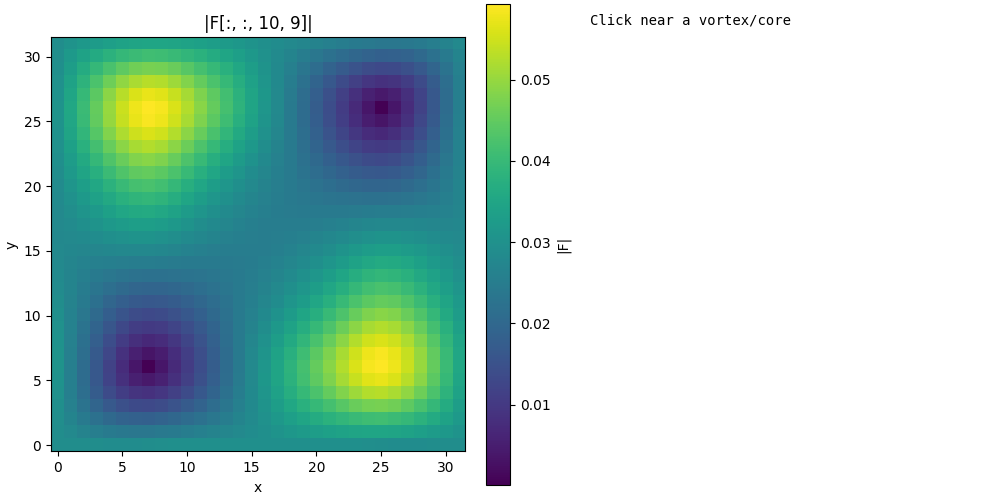

In [160]:
parent_folder = "Data"
folder_name = "2026-05-05_11-38-53"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
Fn_file = os.path.join(load_folder, f"F[0].npy")
#Fn_file = os.path.join(load_folder, f"Z_px10_py9.npy")
F = np.load(Fn_file, mmap_mode='r')
p= (10,9)
explorer = InteractiveWindingExplorer(
    F[:,:,p[0],p[1]],
    radii=[1, 2, 3, 4, 5],
    search_radius=6,
    p=p
    
)

plt.show()

In [ ]:
Qxlist = np.linspace(-np.pi,np.pi,32)
Qylist = np.linspace(-np.pi,np.pi,32)
dQx = Qxlist[1]
dQy = Qylist[1]
arr = (Qxlist[:, None]) + (1j * Qylist[None, :])
np.shape(arr)

In [ ]:
explorer = InteractiveWindingExplorer(
    arr,
    radii=[2, 3, 4, 5, 6],
    search_radius=6,
)

plt.show()

In [ ]:
print(range(1))

In [ ]:
parent_folder = "Data"
folder_name = "2026-03-13_12-10-51"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
Fn_file = os.path.join(load_folder, f"F_keep.npy")
F_keep = np.load(Fn_file, mmap_mode='r')
print(np.shape(F_keep))


In [ ]:
parent_folder = "Data"
folder_name = "test_data"
load_folder = f"{parent_folder}/{folder_name}"
out_folder = f"{load_folder}/test"
pfile = f"{load_folder}/Q_031_015.npz"
arr = np.load(pfile)
f_keep = arr["f_keep"]
n_Fs=1

#### Phase differences between Carolina and Ofir

In [ ]:
cfg = GetConfig("configqwz.yml")
ni_eval, ni_wf = SolveBzNoninteracting(cfg)
ref = np.array([1, 0], dtype=complex)
phase_0 = np.angle(np.einsum('xyi,i->xy', ni_wf[:, :, :, 0], np.conj(ref)))
GraphFromConfig(phase,cfg,GraphProtocol.Test,"Images/Tests",0)
def gauge_fix_cylindrical_gauge(vec, enforce_ky_periodic=True):

    Nkx, Nky, spinor_dim = vec.shape
    vec_gauge = np.zeros((Nkx, Nky, spinor_dim), dtype=np.complex128)

    # seed
    vec_gauge[0, 0, :] = vec[0, 0, :]

    # ky parallel transport on the kx=0 column
    for ky in range(Nky - 1):
        vec_gauge[0, ky + 1, :] = np.exp(-1j * np.angle(np.vdot(vec_gauge[0, ky, :], vec[0, ky + 1, :]))) * vec[0, ky + 1, :]

    # enforce trivial ky sewing (optional)
    if enforce_ky_periodic:
        for ky in range(Nky):
            vec_gauge[0, ky, :] *= np.exp(-1j * ky * np.angle(np.vdot(vec_gauge[0, Nky - 1, :], vec_gauge[0, 0, :])) / Nky)

    # kx parallel transport on each row, seeded by the ky-fixed first column
    for ky in range(Nky):
        for kx in range(Nkx - 1):
            vec_gauge[kx + 1, ky, :] = np.exp(-1j * np.angle(np.vdot(vec_gauge[kx, ky, :], vec[kx + 1, ky, :]))) * vec[kx + 1, ky, :]

    return vec_gauge


uv_cylindrical_gauge = gauge_fix_cylindrical_gauge(ni_wf[:,:,:,0], enforce_ky_periodic=True)
uc_cylindrical_gauge = gauge_fix_cylindrical_gauge(ni_wf[:,:,:,1], enforce_ky_periodic=True)
ref = np.array([1, 0], dtype=complex)
phase = np.angle(np.einsum('xyi,i->xy', uv_cylindrical_gauge, np.conj(ref)))
GraphFromConfig(phase,cfg,GraphProtocol.Test,"Images/Tests",0)

def holonomy_cylindrical_gauge(vec):
    Nkx, Nky, _ = vec.shape

    holonomy = np.zeros(Nky, dtype=np.complex128)

    for ky in range(Nky):
        holonomy[ky] = np.vdot(vec[Nkx - 1, ky, :], vec[0, ky, :]) / abs(np.vdot(vec[Nkx - 1, ky, :], vec[0, ky, :]))

    return holonomy


def extended_state_cylindrical_gauge(vec, gx, kx_idx, ky_idx):
    Nkx, Nky, dim = vec.shape
    nwrap_x = kx_idx // Nkx
    kx_mod = kx_idx % Nkx
    ky_mod = ky_idx % Nky
    return (gx[ky_mod] ** nwrap_x) * vec[kx_mod, ky_mod, :]

gx_v = holonomy_cylindrical_gauge(uv_cylindrical_gauge)
gx_c = holonomy_cylindrical_gauge(uc_cylindrical_gauge)

#### Check phases & phase differences

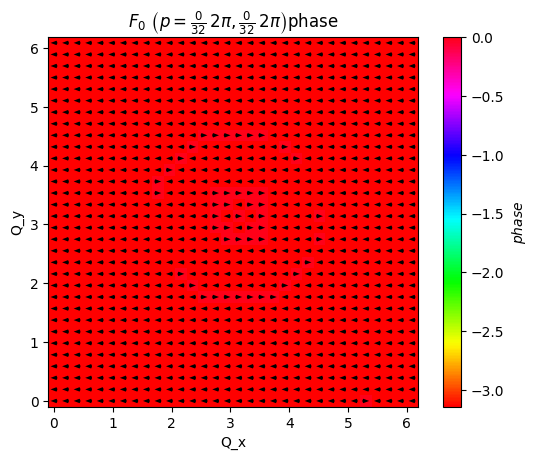

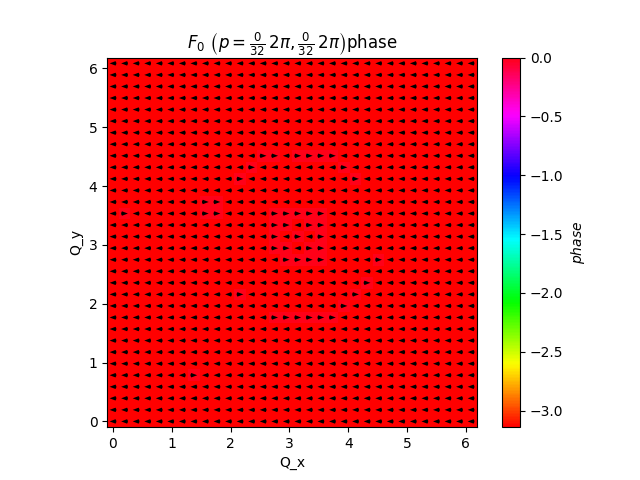

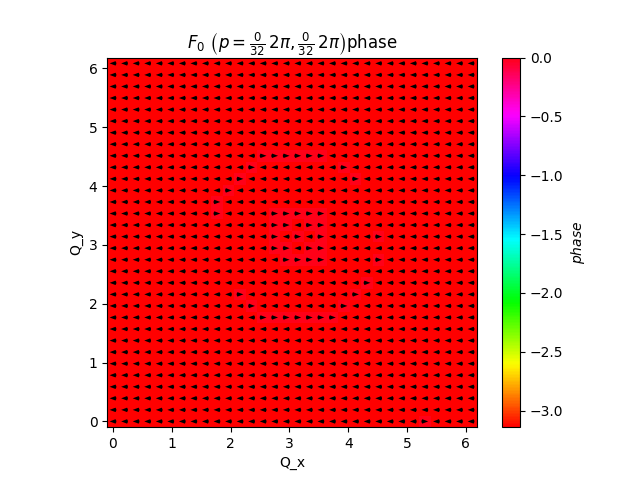

In [153]:
parent_folder = "Data"
#folder_name1 = "test_data"
folder_name1 = "2026-04-29_14-36-00"
foldername_2 = "2026-05-05_11-15-50"
load_folder = f"{parent_folder}/{foldername_2}"
configfile = os.path.join(load_folder, "config.yml")
cfg = GetConfig(configfile)
Fnfile = os.path.join(load_folder, f"F[0].npy")
Fn2 = np.load(Fnfile, mmap_mode='r')
Fn2_p = Fn2[:,:,0,0]
#Fn1file = os.path.join(parent_folder,folder_name1,"Z_px10_py9.npy")
Fn1file = os.path.join(parent_folder,folder_name1, f"F[0].npy")
Fn1 = np.load(Fn1file, mmap_mode='r')
Fn1_p = Fn1[:,:,0,0]
out_folder = f"{load_folder}/test"
GraphFromConfig(np.angle(Fn1_p),cfg, GraphProtocol.FQuiver, out_folder,0,(0,0))
GraphFromConfig(np.angle(Fn2_p),cfg, GraphProtocol.FQuiver, out_folder,0,(0,0))

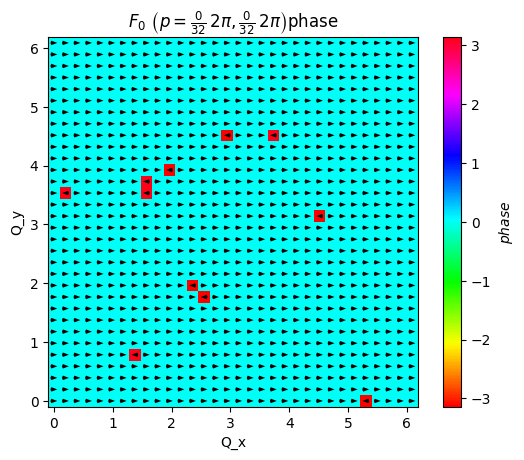

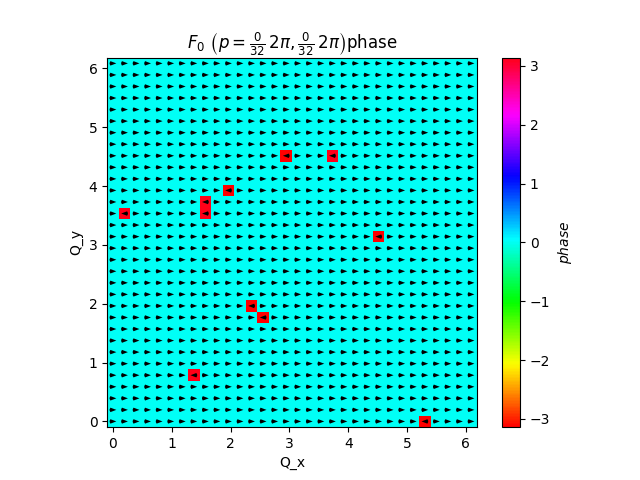

In [152]:
GraphFromConfig(np.angle(Fn1_p)-np.angle(Fn2_p),cfg, GraphProtocol.FQuiver, out_folder,0,(0,0))